In [2]:
from getpass import getpass
api_key = getpass("Enter your API key: ")

Enter your API key:  ········


In [4]:
"""
SCRIPT 3 — Multi-Source News Scraper (RSS + NewsData.io + Reddit)
AI-Powered Supply Chain Disruption Detection — Indian MSME Networks

What this does:
  1. Scrapes 7 RSS feeds (Economic Times, The Hindu, LiveMint)
  2. Queries NewsData.io API with 16 supply-chain-specific search terms
  3. Scrapes Reddit using PRAW (READ-ONLY MODE — no username/password needed)
  4. Filters all sources by relevance keywords
  5. Labels disruption vs normal using a 20-keyword disruption list
  6. Saves everything into one combined file: news_final_labelled.csv

BEFORE RUNNING:
  - Get a NewsData.io key (free): https://newsdata.io
  - Get Reddit API credentials (free, 5 min): https://www.reddit.com/prefs/apps
    -> click "create another app" -> type = "script" -> copy client_id + secret
  - Paste both below in CONFIG

Run this after Script 2 (or independently — it doesn't depend on the graph).
"""

import requests
import feedparser
import json
import csv
import time
import hashlib
import re
import os
from datetime import datetime

import pandas as pd

# ── CONFIG — paste your real keys here ────────────────────────────────────────
PATH = r"C:\Users\DELL\supply_chain_project\data"

NEWSDATA_API_KEY = "pub_4dbe83ec27ae4135ac10051af344cf41"   # your existing key

REDDIT_CLIENT_ID     = "PASTE_YOUR_REDDIT_CLIENT_ID"      # from reddit.com/prefs/apps
REDDIT_CLIENT_SECRET = "PASTE_YOUR_REDDIT_CLIENT_SECRET"  # next to "secret:"
# NOTE: no username/password needed — read-only scraping doesn't require login.
# Using username/password is what caused your earlier 401 errors.

# ── Sources ────────────────────────────────────────────────────────────────────
RSS_FEEDS = {
    "et_industry":       "https://economictimes.indiatimes.com/industry/rssfeeds/13352306.cms",
    "et_economy":        "https://economictimes.indiatimes.com/economy/rssfeeds/1373380680.cms",
    "hindu_business":    "https://www.thehindu.com/business/?service=rss",
    "hindu_economy":     "https://www.thehindu.com/business/Economy/?service=rss",
    "hindu_industry":    "https://www.thehindu.com/business/Industry/?service=rss",
    "livemint_industry": "https://www.livemint.com/rss/industry",
    "livemint_economy":  "https://www.livemint.com/rss/economy",
}

NEWSDATA_QUERIES = [
    "supply chain India MSME", "logistics India small business",
    "warehousing India manufacturing", "procurement India vendor",
    "cold chain India agriculture", "last mile delivery India",
    "freight India export", "MSME supply disruption India",
    "inventory management India", "India import export trade",
    "e-commerce logistics India", "GST logistics India",
    "India packaging distribution", "India supply chain disruption",
    "India trade finance MSME", "India transportation infrastructure",
]

REDDIT_SUBREDDITS = [
    "StartUpIndia", "IndiaBusiness", "india", "IndiaInvestments",
    "supplychain", "logistics",
]

REDDIT_KEYWORDS = [
    "MSME", "supply chain India", "logistics India", "small business India",
    "Udyam", "manufacturing India", "SME India", "mudra loan",
]

RELEVANCE_KEYWORDS = [
    "supply chain", "logistics", "warehouse", "msme", "small business",
    "procurement", "vendor", "cold chain", "last mile", "freight",
    "export", "import", "manufacturing", "inventory", "distribution",
    "packaging", "shipping", "transport", "delivery", "trade",
    "raw material", "supplier",
]

DISRUPTION_KEYWORDS = """
SCRIPT 3 (v2) — Multi-Source News Scraper (RSS + NewsData.io + GDELT + Reddit)
AI-Powered Supply Chain Disruption Detection — Indian MSME Networks

What's new vs v1:
  - API keys moved to .env (never hardcode keys in the script again)
  - RSS feed list expanded from 7 -> 15 feeds (Business Standard, Moneycontrol,
    Financial Express, PTI, more ET/Mint sections)
  - GDELT DOC 2.0 API added back in, with a real rate limiter (min 8s between
    calls) and automatic retry-with-backoff on 429s, instead of firing every
    query back-to-back and dying
  - Reddit scraping kept, read-only mode (no username/password needed)
  - Results now ACCUMULATE across runs: existing news_final_labelled.csv is
    loaded first and merged with new results, deduped by URL hash. Run this
    weekly and your dataset grows instead of resetting every time.

BEFORE RUNNING:
  1. pip install requests feedparser python-dotenv pandas praw --break-system-packages
  2. Create a file called `.env` in the same folder as this script, containing:

       NEWSDATA_API_KEY=your_newsdata_key_here
       REDDIT_CLIENT_ID=your_reddit_client_id_here
       REDDIT_CLIENT_SECRET=your_reddit_client_secret_here

  3. Get a NewsData.io key (free): https://newsdata.io
  4. Get Reddit API credentials (free, 5 min): https://www.reddit.com/prefs/apps
     -> click "create another app" -> type = "script" -> copy client_id + secret
     -> you only need client_id + client_secret, NOT your Reddit username/password.
        Using your real login is what caused the 401 errors before.

Run this after Script 2 (or independently — it doesn't depend on the graph).
"""

import requests
import feedparser
import json
import time
import hashlib
import re
import os
from datetime import datetime

import pandas as pd
from dotenv import load_dotenv

# ── CONFIG — load keys from .env, never hardcode them ─────────────────────────
load_dotenv()

PATH = r"C:\Users\DELL\supply_chain_project\data"

NEWSDATA_API_KEY      = os.getenv("NEWSDATA_API_KEY", "")
REDDIT_CLIENT_ID      = os.getenv("REDDIT_CLIENT_ID", "")
REDDIT_CLIENT_SECRET  = os.getenv("REDDIT_CLIENT_SECRET", "")

if not NEWSDATA_API_KEY:
    print("WARNING: NEWSDATA_API_KEY not found in .env — NewsData.io step will be skipped.")
if not REDDIT_CLIENT_ID or not REDDIT_CLIENT_SECRET:
    print("WARNING: Reddit credentials not found in .env — Reddit step will be skipped.")

# ── Sources ─────────────────────────────────────────────────────────────────────
RSS_FEEDS = {
    # Economic Times
    "et_industry":        "https://economictimes.indiatimes.com/industry/rssfeeds/13352306.cms",
    "et_economy":         "https://economictimes.indiatimes.com/economy/rssfeeds/1373380680.cms",
    "et_smallbiz":        "https://economictimes.indiatimes.com/small-biz/rssfeeds/13358067.cms",
    "et_transportation":  "https://economictimes.indiatimes.com/industry/transportation/rssfeeds/13358300.cms",
    # The Hindu
    "hindu_business":     "https://www.thehindu.com/business/?service=rss",
    "hindu_economy":      "https://www.thehindu.com/business/Economy/?service=rss",
    "hindu_industry":     "https://www.thehindu.com/business/Industry/?service=rss",
    # Livemint
    "livemint_industry":  "https://www.livemint.com/rss/industry",
    "livemint_economy":   "https://www.livemint.com/rss/economy",
    "livemint_companies": "https://www.livemint.com/rss/companies",
    # Business Standard
    "bs_economy":         "https://www.business-standard.com/rss/economy-policy-10601.rss",
    "bs_companies":       "https://www.business-standard.com/rss/companies-101.rss",
    "bs_industry":        "https://www.business-standard.com/rss/industry-102.rss",
    # Moneycontrol
    "mc_economy":         "https://www.moneycontrol.com/rss/economy.xml",
    "mc_business":        "https://www.moneycontrol.com/rss/business.xml",
    # Financial Express
    "fe_industry":        "https://www.financialexpress.com/industry/feed/",
}

NEWSDATA_QUERIES = [
    "supply chain India MSME", "logistics India small business",
    "warehousing India manufacturing", "procurement India vendor",
    "cold chain India agriculture", "last mile delivery India",
    "freight India export", "MSME supply disruption India",
    "inventory management India", "India import export trade",
    "e-commerce logistics India", "GST logistics India",
    "India packaging distribution", "India supply chain disruption",
    "India trade finance MSME", "India transportation infrastructure",
]

# GDELT queries — one string per disruption type, same categories as before
GDELT_QUERIES = {
    "raw_material_shortage": (
        '("raw material shortage" OR "material shortage" OR "steel shortage" '
        'OR "coal shortage" OR "input shortage" OR "commodity shortage") '
        'sourcecountry:india'
    ),
    "transport_disruption": (
        '("truckers strike" OR "truck strike" OR "transport strike" '
        'OR "logistics disruption" OR "goods movement halted" '
        'OR "highway blocked") sourcecountry:india'
    ),
    "natural_disaster": (
        '("flood damage factory" OR "cyclone damage" OR "earthquake damage" '
        'OR "flood disrupts" OR "heatwave factory" OR "disaster supply chain") '
        'sourcecountry:india'
    ),
    "policy_shock": (
        '("export ban" OR "import ban" OR "export restriction" '
        'OR "MSME policy" OR "GST disruption" OR "customs delay") '
        'sourcecountry:india'
    ),
    "factory_shutdown": (
        '("factory shutdown" OR "factory closed" OR "plant shutdown" '
        'OR "manufacturing unit closed" OR "power cut factory" '
        'OR "production halt") sourcecountry:india'
    ),
    "port_logistics_delay": (
        '("port congestion" OR "port delay" OR "Mumbai port" '
        'OR "container delay" OR "shipping delay India" '
        'OR "cargo stuck") sourcecountry:india'
    ),
}

REDDIT_SUBREDDITS = [
    "StartUpIndia", "IndiaBusiness", "india", "IndiaInvestments",
    "supplychain", "logistics",
]

REDDIT_KEYWORDS = [
    "MSME", "supply chain India", "logistics India", "small business India",
    "Udyam", "manufacturing India", "SME India", "mudra loan",
]

RELEVANCE_KEYWORDS = [
    "supply chain", "logistics", "warehouse", "msme", "small business",
    "procurement", "vendor", "cold chain", "last mile", "freight",
    "export", "import", "manufacturing", "inventory", "distribution",
    "packaging", "shipping", "transport", "delivery", "trade",
    "raw material", "supplier",
]

DISRUPTION_KEYWORDS = [
    "strike", "flood", "shortage", "delay", "disruption", "closure",
    "shutdown", "halt", "blockade", "congestion", "outage", "drought",
    "cyclone", "protest", "tariff", "ban", "hike", "unrest", "damage",
    "fire", "earthquake", "accident",
]

HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/120.0.0.0 Safari/537.36"
}

# ── Shared state ─────────────────────────────────────────────────────────────
seen_ids = set()
records  = []


def clean(text):
    text = re.sub(r"<[^>]+>", " ", text or "")
    return re.sub(r"\s+", " ", text).strip()


def make_id(url):
    return hashlib.md5(url.encode()).hexdigest()[:12]


def is_relevant(title, snippet):
    combined = (title + " " + snippet).lower()
    return any(kw in combined for kw in RELEVANCE_KEYWORDS)


def is_disruption(title, snippet):
    combined = (title + " " + snippet).lower()
    return int(any(kw in combined for kw in DISRUPTION_KEYWORDS))


def add_record(title, snippet, source, url, pub_date, origin):
    uid = make_id(url)
    if uid in seen_ids:
        return False
    seen_ids.add(uid)
    if not is_relevant(title, snippet):
        return False
    records.append({
        "id": uid,
        "title": clean(title),
        "snippet": clean(snippet)[:500],
        "source": source,
        "pub_date": pub_date,
        "origin": origin,
        "is_disruption": is_disruption(title, snippet),
    })
    return True


def load_existing_ids():
    """Load previously-collected article IDs so re-runs accumulate instead of
    duplicating or overwriting."""
    out_csv = os.path.join(PATH, "news_final_labelled.csv")
    if os.path.exists(out_csv):
        try:
            df_old = pd.read_csv(out_csv)
            if "id" in df_old.columns:
                for uid in df_old["id"]:
                    seen_ids.add(str(uid))
            print(f"Loaded {len(df_old)} previously-collected articles (will accumulate, not overwrite).")
            return df_old
        except Exception as ex:
            print(f"Could not load existing file, starting fresh: {ex}")
    return None


# ── STEP 1 — RSS feeds ────────────────────────────────────────────────────────
def scrape_rss():
    print("\n-- RSS FEEDS --")
    for name, url in RSS_FEEDS.items():
        try:
            r = requests.get(url, headers=HEADERS, timeout=12)
            feed = feedparser.parse(r.content)
            count = 0
            for e in feed.entries:
                if not e.get("title") or not e.get("link"):
                    continue
                pub = ""
                for field in ("published_parsed", "updated_parsed"):
                    val = getattr(e, field, None)
                    if val:
                        try:
                            pub = datetime(*val[:6]).strftime("%Y-%m-%d")
                            break
                        except Exception:
                            pass
                snippet = e.get("summary", "") or e.get("description", "")
                if add_record(e.title, snippet, name, e.link, pub, "rss"):
                    count += 1
            print(f"  +{count:>4}  {name}")
            time.sleep(1)
        except Exception as ex:
            print(f"  ERR {name}: {ex}")


# ── STEP 2 — NewsData.io ──────────────────────────────────────────────────────
def scrape_newsdata():
    print("\n-- NEWSDATA.IO --")
    if not NEWSDATA_API_KEY:
        print("  Skipped — no NEWSDATA_API_KEY in .env")
        return

    for query in NEWSDATA_QUERIES:
        page_token = None
        for _ in range(3):
            try:
                params = {"apikey": NEWSDATA_API_KEY, "q": query, "country": "in", "language": "en"}
                if page_token:
                    params["page"] = page_token
                data = requests.get("https://newsdata.io/api/1/news", params=params, timeout=15).json()
                if data.get("status") != "success":
                    print(f"  ERR [{query[:40]}]: {data.get('results', {}).get('message', data)}")
                    break
                count = 0
                for a in data.get("results", []):
                    if not a.get("title") or not a.get("link"):
                        continue
                    snippet = a.get("description", "") or a.get("content", "")
                    pub = (a.get("pubDate") or "")[:10]
                    if add_record(a["title"], snippet, "newsdata", a["link"], pub, "newsdata"):
                        count += 1
                print(f"  +{count:>4}  [{query[:45]}]")
                page_token = data.get("nextPage")
                if not page_token:
                    break
                time.sleep(1.5)
            except Exception as ex:
                print(f"  ERR [{query}]: {ex}")
                break


# ── STEP 3 — GDELT (rate-limited, with retry-on-429) ──────────────────────────
GDELT_MIN_INTERVAL = 8   # seconds between GDELT calls — free tier is strict
_last_gdelt_call = [0.0]


def _gdelt_wait():
    elapsed = time.time() - _last_gdelt_call[0]
    if elapsed < GDELT_MIN_INTERVAL:
        time.sleep(GDELT_MIN_INTERVAL - elapsed)


def gdelt_fetch(label, query, max_retries=4):
    url = "https://api.gdeltproject.org/api/v2/doc/doc"
    params = {
        "query":      query,
        "mode":       "artlist",
        "maxrecords": "250",
        "format":     "json",
        "sort":       "datedesc",
        "sourcelang": "english",
    }

    for attempt in range(1, max_retries + 1):
        _gdelt_wait()
        _last_gdelt_call[0] = time.time()
        try:
            resp = requests.get(url, params=params, timeout=30)
            if resp.status_code == 429:
                backoff = GDELT_MIN_INTERVAL * attempt * 2
                print(f"    429 on [{label}], attempt {attempt}/{max_retries} — waiting {backoff}s")
                time.sleep(backoff)
                continue
            resp.raise_for_status()
            data = resp.json()
            return data.get("articles", [])
        except Exception as ex:
            print(f"    ERR [{label}] attempt {attempt}: {ex}")
            time.sleep(GDELT_MIN_INTERVAL)

    print(f"    Giving up on [{label}] after {max_retries} attempts.")
    return []


def scrape_gdelt():
    print("\n-- GDELT --")
    for label, query in GDELT_QUERIES.items():
        articles = gdelt_fetch(label, query)
        count = 0
        for a in articles:
            title = a.get("title", "")
            url_  = a.get("url", "")
            if not title or not url_:
                continue
            pub = a.get("seendate", "")
            try:
                pub = datetime.strptime(pub, "%Y%m%dT%H%M%SZ").strftime("%Y-%m-%d")
            except Exception:
                pass
            snippet = a.get("socialimage", "") and "" or ""  # GDELT artlist has no snippet field
            if add_record(title, snippet, a.get("domain", "gdelt"), url_, pub, f"gdelt_{label}"):
                count += 1
        print(f"  +{count:>4}  {label}")


# ── STEP 4 — Reddit (PRAW, read-only, no login needed) ────────────────────────
def scrape_reddit():
    print("\n-- REDDIT --")

    if not REDDIT_CLIENT_ID or not REDDIT_CLIENT_SECRET:
        print("  Skipped — REDDIT_CLIENT_ID / REDDIT_CLIENT_SECRET not in .env")
        print("  Get them free at: https://www.reddit.com/prefs/apps")
        return

    try:
        import praw
    except ImportError:
        print("  Skipped — praw not installed. Run: pip install praw --break-system-packages")
        return

    try:
        reddit = praw.Reddit(
            client_id=REDDIT_CLIENT_ID,
            client_secret=REDDIT_CLIENT_SECRET,
            user_agent="msme_supply_chain_scraper/2.0",
            # No username/password -> praw uses read-only application-only auth,
            # which is all scraping needs. Using a real login is what caused
            # the earlier 401 errors.
        )
        print(f"  Connected. Read-only mode: {reddit.read_only}")
    except Exception as ex:
        print(f"  ERR connecting to Reddit: {ex}")
        return

    for sub_name in REDDIT_SUBREDDITS:
        for keyword in REDDIT_KEYWORDS:
            try:
                count = 0
                for post in reddit.subreddit(sub_name).search(keyword, sort="new", time_filter="month", limit=25):
                    if not post.title:
                        continue
                    snippet = post.selftext or ""
                    url = f"https://reddit.com{post.permalink}"
                    pub = datetime.utcfromtimestamp(post.created_utc).strftime("%Y-%m-%d")
                    if add_record(post.title, snippet, f"reddit_r/{sub_name}", url, pub, "reddit"):
                        count += 1
                if count:
                    print(f"  +{count:>4}  r/{sub_name} + '{keyword}'")
                time.sleep(1)  # polite pacing between search calls
            except Exception as ex:
                print(f"  ERR r/{sub_name} + '{keyword}': {ex}")
                continue


# ── STEP 5 — Save everything (accumulate, don't overwrite) ────────────────────
def save_results(df_old):
    out_csv   = os.path.join(PATH, "news_final_labelled.csv")
    out_jsonl = os.path.join(PATH, "news_final_labelled.jsonl")

    df_new = pd.DataFrame(records)

    if df_old is not None and not df_old.empty:
        df = pd.concat([df_old, df_new], ignore_index=True)
    else:
        df = df_new

    if df.empty:
        print("\nNo records collected at all (old or new). Check your API keys and internet connection.")
        return

    df = df.drop_duplicates(subset=["id"]).drop_duplicates(subset=["title"])

    df.to_csv(out_csv, index=False)
    with open(out_jsonl, "w", encoding="utf-8") as f:
        for rec in df.to_dict("records"):
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")

    print("\n" + "=" * 60)
    print("  FINAL SUMMARY")
    print("=" * 60)
    print(f"New articles this run : {len(df_new)}")
    print(f"Total after merge     : {len(df)}")
    print(f"Disruption count      : {df['is_disruption'].sum()} ({df['is_disruption'].mean()*100:.1f}%)")
    print(f"Normal count          : {(df['is_disruption']==0).sum()}")
    print(f"\nBy source:")
    print(df["source"].value_counts().to_string())
    print(f"\nBy origin:")
    print(df["origin"].value_counts().to_string())
    print(f"\nSaved: {out_csv}")
    print(f"Saved: {out_jsonl}")


def main():
    print("=" * 60)
    print("  STEP 3 (v2) — Multi-source news scraping")
    print("=" * 60)

    df_old = load_existing_ids()

    scrape_rss()
    scrape_newsdata()
    scrape_gdelt()
    scrape_reddit()
    save_results(df_old)

    print("\nNext step: run Script 4 (NLP model training)")


if __name__ == "__main__":
    main()[
    "strike", "flood", "shortage", "delay", "disruption", "closure",
    "shutdown", "halt", "blockade", "congestion", "outage", "drought",
    "cyclone", "protest", "tariff", "ban", "hike", "unrest", "damage",
    "fire", "earthquake", "accident",
]

HEADERS = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/120.0.0.0 Safari/537.36"}

# ── Shared state ───────────────────────────────────────────────────────────────
seen_ids = set()
records  = []


def clean(text):
    text = re.sub(r"<[^>]+>", " ", text or "")
    return re.sub(r"\s+", " ", text).strip()


def make_id(url):
    return hashlib.md5(url.encode()).hexdigest()[:12]


def is_relevant(title, snippet):
    combined = (title + " " + snippet).lower()
    return any(kw in combined for kw in RELEVANCE_KEYWORDS)


def is_disruption(title, snippet):
    combined = (title + " " + snippet).lower()
    return int(any(kw in combined for kw in DISRUPTION_KEYWORDS))


def add_record(title, snippet, source, url, pub_date, origin):
    uid = make_id(url)
    if uid in seen_ids:
        return False
    seen_ids.add(uid)
    if not is_relevant(title, snippet):
        return False
    records.append({
        "id": uid,
        "title": clean(title),
        "snippet": clean(snippet)[:500],
        "source": source,
        "pub_date": pub_date,
        "origin": origin,
        "is_disruption": is_disruption(title, snippet),
    })
    return True


# ── STEP 1 — RSS feeds ──────────────────────────────────────────────────────────
def scrape_rss():
    print("\n-- RSS FEEDS --")
    for name, url in RSS_FEEDS.items():
        try:
            r = requests.get(url, headers=HEADERS, timeout=12)
            feed = feedparser.parse(r.content)
            count = 0
            for e in feed.entries:
                if not e.get("title") or not e.get("link"):
                    continue
                pub = ""
                for field in ("published_parsed", "updated_parsed"):
                    val = getattr(e, field, None)
                    if val:
                        try:
                            pub = datetime(*val[:6]).strftime("%Y-%m-%d")
                            break
                        except Exception:
                            pass
                snippet = e.get("summary", "") or e.get("description", "")
                if add_record(e.title, snippet, name, e.link, pub, "rss"):
                    count += 1
            print(f"  +{count:>4}  {name}")
            time.sleep(1)
        except Exception as ex:
            print(f"  ERR {name}: {ex}")


# ── STEP 2 — NewsData.io ────────────────────────────────────────────────────────
def scrape_newsdata():
    print("\n-- NEWSDATA.IO --")
    if NEWSDATA_API_KEY.startswith("pub_") is False:
        print("  Skipped — no valid NewsData.io key set in CONFIG")
        return

    for query in NEWSDATA_QUERIES:
        page_token = None
        for _ in range(3):
            try:
                params = {"apikey": NEWSDATA_API_KEY, "q": query, "country": "in", "language": "en"}
                if page_token:
                    params["page"] = page_token
                data = requests.get("https://newsdata.io/api/1/news", params=params, timeout=15).json()
                if data.get("status") != "success":
                    break
                count = 0
                for a in data.get("results", []):
                    if not a.get("title") or not a.get("link"):
                        continue
                    snippet = a.get("description", "") or a.get("content", "")
                    pub = (a.get("pubDate") or "")[:10]
                    if add_record(a["title"], snippet, "newsdata", a["link"], pub, "newsdata"):
                        count += 1
                print(f"  +{count:>4}  [{query[:45]}]")
                page_token = data.get("nextPage")
                if not page_token:
                    break
                time.sleep(1.5)
            except Exception as ex:
                print(f"  ERR [{query}]: {ex}")
                break


# ── STEP 3 — Reddit (PRAW, read-only, no login needed) ─────────────────────────
def scrape_reddit():
    print("\n-- REDDIT --")

    if "PASTE_YOUR" in REDDIT_CLIENT_ID:
        print("  Skipped — paste your Reddit client_id and client_secret in CONFIG")
        print("  Get them free at: https://www.reddit.com/prefs/apps")
        return

    try:
        import praw
    except ImportError:
        print("  Skipped — praw not installed. Run: pip install praw")
        return

    try:
        reddit = praw.Reddit(
            client_id=REDDIT_CLIENT_ID,
            client_secret=REDDIT_CLIENT_SECRET,
            user_agent="msme_supply_chain_scraper/1.0",
            # NOTE: no username/password -> praw automatically uses
            # read-only application-only auth, which is all scraping needs.
        )
        print(f"  Connected. Read-only mode: {reddit.read_only}")
    except Exception as ex:
        print(f"  ERR connecting to Reddit: {ex}")
        return

    for sub_name in REDDIT_SUBREDDITS:
        for keyword in REDDIT_KEYWORDS:
            try:
                count = 0
                for post in reddit.subreddit(sub_name).search(keyword, sort="new", time_filter="month", limit=25):
                    if not post.title:
                        continue
                    snippet = post.selftext or ""
                    url = f"https://reddit.com{post.permalink}"
                    pub = datetime.utcfromtimestamp(post.created_utc).strftime("%Y-%m-%d")
                    if add_record(post.title, snippet, f"reddit_r/{sub_name}", url, pub, "reddit"):
                        count += 1
                if count:
                    print(f"  +{count:>4}  r/{sub_name} + '{keyword}'")
            except Exception as ex:
                print(f"  ERR r/{sub_name} + '{keyword}': {ex}")
                continue


# ── STEP 4 — Save everything ────────────────────────────────────────────────────
def save_results():
    if not records:
        print("\nNo records collected at all. Check your API keys and internet connection.")
        return

    df = pd.DataFrame(records).drop_duplicates(subset=["title"])

    out_csv = os.path.join(PATH, "news_final_labelled.csv")
    df.to_csv(out_csv, index=False)

    out_jsonl = os.path.join(PATH, "news_final_labelled.jsonl")
    with open(out_jsonl, "w", encoding="utf-8") as f:
        for rec in df.to_dict("records"):
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")

    print("\n" + "=" * 60)
    print("  FINAL SUMMARY")
    print("=" * 60)
    print(f"Total articles     : {len(df)}")
    print(f"Disruption count   : {df['is_disruption'].sum()} ({df['is_disruption'].mean()*100:.1f}%)")
    print(f"Normal count       : {(df['is_disruption']==0).sum()}")
    print(f"\nBy source:")
    print(df["source"].value_counts().to_string())
    print(f"\nBy origin:")
    print(df["origin"].value_counts().to_string())
    print(f"\nSaved: {out_csv}")
    print(f"Saved: {out_jsonl}")


def main():
    print("=" * 60)
    print("  STEP 3 — Multi-source news scraping")
    print("=" * 60)

    scrape_rss()
    scrape_newsdata()
    scrape_reddit()
    save_results()

    print("\nNext step: run Script 4 (NLP model training)")


if __name__ == "__main__":
    main()

  STEP 3 (v2) — Multi-source news scraping
Loaded 712 previously-collected articles (will accumulate, not overwrite).

-- RSS FEEDS --
  +   1  et_industry
  +   0  et_economy
  +   0  et_smallbiz
  +   0  et_transportation
  +   0  hindu_business
  +   0  hindu_economy
  +   0  hindu_industry
  +   0  livemint_industry
  +   1  livemint_economy
  +   0  livemint_companies
  +   0  bs_economy
  +   0  bs_companies
  +   0  bs_industry
  +   0  mc_economy
  +   0  mc_business
  +   0  fe_industry

-- NEWSDATA.IO --
  Skipped — no NEWSDATA_API_KEY in .env

-- GDELT --
  +   0  raw_material_shortage
    429 on [transport_disruption], attempt 1/4 — waiting 16s
    429 on [transport_disruption], attempt 2/4 — waiting 32s
    429 on [transport_disruption], attempt 3/4 — waiting 48s
    429 on [transport_disruption], attempt 4/4 — waiting 64s
    Giving up on [transport_disruption] after 4 attempts.
  +   0  transport_disruption
    429 on [natural_disaster], attempt 1/4 — waiting 16s
  +   0

TypeError: 'NoneType' object is not subscriptable

In [ ]:
"""
SCRIPT 4 — NLP Disruption Classifier (TF-IDF baseline + DistilBERT fine-tune)
AI-Powered Supply Chain Disruption Detection — Indian MSME Networks

What this does:
  PART A — TF-IDF baseline (kept from original project)
    1. Loads news_final_labelled.csv (real articles from Script 3)
    2. Trains 4 classifiers: Logistic Regression, Random Forest, SVM, Naive Bayes
    3. Picks the best by F1-score, saves it + evaluation charts

  PART B — DistilBERT fine-tuning (new, upgraded model)
    1. Fine-tunes distilbert-base-uncased on the same real articles
    2. Evaluates with confusion matrix + AUC-ROC
    3. Saves the model + per-article disruption probability
    4. Aggregates disruption signal per state -> feeds Script 6 (resilience scoring)

Run this after Script 3.
"""

import os
import pickle
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, roc_auc_score, roc_curve, confusion_matrix
)

PATH = r"C:\Users\DELL\supply_chain_project\data"


# ════════════════════════════════════════════════════════════════════════════
# PART A — TF-IDF baseline (4-model comparison)
# ════════════════════════════════════════════════════════════════════════════

def load_news():
    news_path = os.path.join(PATH, "news_final_labelled.csv")
    df = pd.read_csv(news_path)
    df["text"] = df["title"].fillna("") + " " + df["snippet"].fillna("")
    df = df[df["text"].str.len() > 5].reset_index(drop=True)
    return df


def train_tfidf_models(df):
    print("=" * 60)
    print("  PART A — TF-IDF baseline (4-model comparison)")
    print("=" * 60)

    X = df["text"]
    y = df["is_disruption"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    print(f"Training samples : {len(X_train)}")
    print(f"Testing samples  : {len(X_test)}")

    tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=1000, stop_words="english")
    X_train_tfidf = tfidf.fit_transform(X_train)
    X_test_tfidf  = tfidf.transform(X_test)

    models = {
        "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
        "Random Forest":       RandomForestClassifier(n_estimators=100, random_state=42),
        "SVM":                 SVC(probability=True, random_state=42),
        "Naive Bayes":         MultinomialNB(),
    }

    results = {}
    best_model, best_score, best_name = None, 0, ""

    print("\n=== MODEL COMPARISON ===")
    for name, model in models.items():
        model.fit(X_train_tfidf, y_train)
        y_pred = model.predict(X_test_tfidf)
        y_prob = model.predict_proba(X_test_tfidf)[:, 1]

        report = classification_report(
            y_test, y_pred, target_names=["Not Disruption", "Disruption"],
            zero_division=0, output_dict=True
        )
        f1  = report["weighted avg"]["f1-score"]
        acc = report["accuracy"]
        auc = roc_auc_score(y_test, y_prob)

        results[name] = {"accuracy": acc, "f1": f1, "auc": auc,
                          "y_pred": y_pred, "y_prob": y_prob}

        print(f"\n{name}")
        print(f"  Accuracy : {acc*100:.2f}%")
        print(f"  F1 Score : {f1*100:.2f}%")
        print(f"  ROC-AUC  : {auc*100:.2f}%")

        if f1 > best_score:
            best_score, best_model, best_name = f1, model, name

    print(f"\n=== BEST MODEL: {best_name} (F1 = {best_score*100:.2f}%) ===")

    # Save best model
    pickle.dump(best_model, open(os.path.join(PATH, "nlp_model.pkl"), "wb"))
    pickle.dump(tfidf,      open(os.path.join(PATH, "tfidf_vectorizer.pkl"), "wb"))
    print(f"Saved: nlp_model.pkl ({best_name})")
    print(f"Saved: tfidf_vectorizer.pkl")

    # ── Evaluation charts ──────────────────────────────────────────────────────
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Confusion matrix for best model
    cm = confusion_matrix(y_test, results[best_name]["y_pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Purples",
                xticklabels=["Normal", "Disruption"],
                yticklabels=["Normal", "Disruption"], ax=axes[0])
    axes[0].set_title(f"Confusion Matrix — {best_name}")
    axes[0].set_xlabel("Predicted")
    axes[0].set_ylabel("Actual")

    # AUC-ROC for best model
    fpr, tpr, _ = roc_curve(y_test, results[best_name]["y_prob"])
    axes[1].plot(fpr, tpr, color="#7F77DD", linewidth=2.5,
                 label=f"AUC = {results[best_name]['auc']:.3f}")
    axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4, label="Random")
    axes[1].fill_between(fpr, tpr, alpha=0.1, color="#7F77DD")
    axes[1].set_title(f"AUC-ROC Curve — {best_name}")
    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    # Model comparison bar chart
    names  = list(results.keys())
    aucs   = [results[n]["auc"] * 100 for n in names]
    colors = ["#7F77DD", "#1D9E75", "#D85A30", "#BA7517"]
    bars = axes[2].bar(names, aucs, color=colors, edgecolor="white")
    axes[2].set_title("AUC-ROC Comparison — All 4 Models")
    axes[2].set_ylabel("AUC-ROC (%)")
    axes[2].set_ylim(0, 105)
    axes[2].tick_params(axis="x", rotation=20)
    for bar, val in zip(bars, aucs):
        axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                     f"{val:.1f}%", ha="center", fontweight="bold", fontsize=9)

    plt.tight_layout()
    chart_path = os.path.join(PATH, "tfidf_model_evaluation.png")
    plt.savefig(chart_path, dpi=150, bbox_inches="tight")
    plt.close()
    print(f"Saved: {chart_path}")

    # Live predictions sanity check
    test_headlines = [
        "Truckers strike disrupts supply chain in Gujarat",
        "Sensex rises 400 points today",
        "Flood damages textile factories in Surat",
        "RBI keeps interest rates unchanged",
        "Cotton shortage hits MSME manufacturers in Rajasthan",
        "Port congestion at Mumbai delays containers",
    ]
    print("\n=== LIVE PREDICTIONS (best model) ===")
    for headline in test_headlines:
        vec  = tfidf.transform([headline])
        pred = best_model.predict(vec)[0]
        prob = best_model.predict_proba(vec)[0][pred]
        label = "DISRUPTION" if pred == 1 else "NOT DISRUPTION"
        print(f"  {label:14} ({prob*100:.0f}%) -> {headline}")

    return best_name, results


# ════════════════════════════════════════════════════════════════════════════
# PART B — DistilBERT fine-tuning
# ════════════════════════════════════════════════════════════════════════════

def train_distilbert(df):
    print("\n" + "=" * 60)
    print("  PART B — DistilBERT fine-tuning")
    print("=" * 60)

    try:
        import torch
        from torch.utils.data import Dataset, DataLoader
        from transformers import (
            DistilBertTokenizer, DistilBertForSequenceClassification,
            get_linear_schedule_with_warmup
        )
        from torch.optim import AdamW
    except ImportError:
        print("  Skipped — install with: pip install torch transformers")
        return None

    if len(df) < 80:
        print(f"  WARNING: only {len(df)} articles. DistilBERT needs more data to")
        print(f"  generalise well. Consider adding Reddit data (Script 3) first.")
        print(f"  Proceeding anyway since this is acceptable for an academic project.")

    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Device: {DEVICE}")

    X = df["text"].tolist()
    y = df["is_disruption"].tolist()

    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=y
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.5, random_state=42
    )
    print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

    MODEL_NAME = "distilbert-base-uncased"
    tokenizer  = DistilBertTokenizer.from_pretrained(MODEL_NAME)
    MAX_LEN    = 128

    class DisruptionDataset(Dataset):
        def __init__(self, texts, labels):
            self.texts, self.labels = texts, labels

        def __len__(self):
            return len(self.texts)

        def __getitem__(self, idx):
            enc = tokenizer(self.texts[idx], max_length=MAX_LEN, padding="max_length",
                             truncation=True, return_tensors="pt")
            return {
                "input_ids": enc["input_ids"].squeeze(),
                "attention_mask": enc["attention_mask"].squeeze(),
                "label": torch.tensor(self.labels[idx], dtype=torch.long),
            }

    BATCH_SIZE = 16  # smaller batch since dataset is modest in size
    train_loader = DataLoader(DisruptionDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
    val_loader   = DataLoader(DisruptionDataset(X_val, y_val), batch_size=BATCH_SIZE)
    test_loader  = DataLoader(DisruptionDataset(X_test, y_test), batch_size=BATCH_SIZE)

    model = DistilBertForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(DEVICE)

    EPOCHS = 4
    optimizer = AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
    total_steps = len(train_loader) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=total_steps // 10, num_training_steps=total_steps
    )

    def run_epoch(loader, train=True):
        model.train() if train else model.eval()
        total_loss, correct, total = 0, 0, 0
        all_preds, all_probs, all_labels = [], [], []
        for batch in loader:
            input_ids = batch["input_ids"].to(DEVICE)
            attn      = batch["attention_mask"].to(DEVICE)
            labels    = batch["label"].to(DEVICE)

            if train:
                optimizer.zero_grad()
            outputs = model(input_ids=input_ids, attention_mask=attn, labels=labels)
            loss, logits = outputs.loss, outputs.logits

            if train:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                scheduler.step()

            probs = torch.softmax(logits, dim=1)[:, 1]
            preds = torch.argmax(logits, dim=1)

            total_loss += loss.item()
            correct += (preds == labels).sum().item()
            total += labels.size(0)
            all_preds.extend(preds.detach().cpu().numpy())
            all_probs.extend(probs.detach().cpu().numpy())
            all_labels.extend(labels.detach().cpu().numpy())

        return total_loss / len(loader), correct / total, all_preds, all_probs, all_labels

    best_val_loss = float("inf")
    print("\nTraining...")
    for epoch in range(EPOCHS):
        tr_loss, tr_acc, *_ = run_epoch(train_loader, train=True)
        val_loss, val_acc, *_ = run_epoch(val_loader, train=False)
        print(f"  Epoch {epoch+1}/{EPOCHS} | train_loss={tr_loss:.4f} train_acc={tr_acc:.4f} "
              f"| val_loss={val_loss:.4f} val_acc={val_acc:.4f}")
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            model.save_pretrained(os.path.join(PATH, "distilbert_disruption"))
            tokenizer.save_pretrained(os.path.join(PATH, "distilbert_disruption"))
            print("    -> best model saved")

    # ── Evaluate on test set ──────────────────────────────────────────────────
    best_model = DistilBertForSequenceClassification.from_pretrained(
        os.path.join(PATH, "distilbert_disruption")
    ).to(DEVICE)

    _, test_acc, test_preds, test_probs, test_labels = run_epoch(test_loader, train=False)
    test_auc = roc_auc_score(test_labels, test_probs)

    print("\n=== DISTILBERT TEST RESULTS ===")
    print(f"Accuracy : {test_acc:.4f}")
    print(f"AUC-ROC  : {test_auc:.4f}")
    print(classification_report(test_labels, test_preds, target_names=["Normal", "Disruption"]))

    # Charts
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    cm = confusion_matrix(test_labels, test_preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Purples",
                xticklabels=["Normal", "Disruption"], yticklabels=["Normal", "Disruption"], ax=axes[0])
    axes[0].set_title("DistilBERT Confusion Matrix")

    fpr, tpr, _ = roc_curve(test_labels, test_probs)
    axes[1].plot(fpr, tpr, color="#1D9E75", linewidth=2.5, label=f"AUC = {test_auc:.3f}")
    axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
    axes[1].set_title("DistilBERT AUC-ROC")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(PATH, "distilbert_evaluation.png"), dpi=150, bbox_inches="tight")
    plt.close()
    print(f"Saved: distilbert_evaluation.png")

    # ── Score ALL articles with the trained model ─────────────────────────────
    def predict_batch(texts, batch_size=32):
        model.eval()
        all_probs = []
        for i in range(0, len(texts), batch_size):
            batch = texts[i:i+batch_size]
            enc = tokenizer(batch, max_length=MAX_LEN, padding=True, truncation=True, return_tensors="pt")
            with torch.no_grad():
                out = best_model(input_ids=enc["input_ids"].to(DEVICE),
                                  attention_mask=enc["attention_mask"].to(DEVICE))
                probs = torch.softmax(out.logits, dim=1)[:, 1]
                all_probs.extend(probs.cpu().numpy())
        return all_probs

    df["bert_disruption_prob"] = predict_batch(df["text"].tolist())
    df.to_csv(os.path.join(PATH, "news_final_labelled.csv"), index=False)
    print(f"Updated news_final_labelled.csv with bert_disruption_prob column")

    return df


# ════════════════════════════════════════════════════════════════════════════
def main():
    df = load_news()
    print(f"Loaded {len(df)} articles | Disruption: {df['is_disruption'].sum()} "
          f"({df['is_disruption'].mean()*100:.1f}%)")

    best_name, tfidf_results = train_tfidf_models(df)
    df_scored = train_distilbert(df)

    print("\n" + "=" * 60)
    print("  STAGE 3 COMPLETE")
    print("=" * 60)
    print("Output files:")
    print("  nlp_model.pkl                  — best TF-IDF classifier")
    print("  tfidf_vectorizer.pkl           — fitted vectorizer")
    print("  tfidf_model_evaluation.png     — confusion matrix + ROC + comparison")
    print("  distilbert_disruption/         — fine-tuned DistilBERT model")
    print("  distilbert_evaluation.png      — DistilBERT confusion matrix + ROC")
    print("  news_final_labelled.csv        — updated with bert_disruption_prob")
    print("\nNext step: run Script 5 (Graph Neural Network)")


if __name__ == "__main__":
    main()

In [ ]:
"""
SCRIPT 0 — Folder Audit
AI-Powered Supply Chain Disruption Detection — Indian MSME Networks

What this does:
  Scans your entire data folder and tells you, file by file:
    - what it is
    - whether it's GOOD (keep), JUNK (delete), or NEEDS WORK
    - how many rows/size it has
    - which pipeline script produced it or needs it

Run this FIRST, before anything else. It won't change or delete anything —
it only reads and reports. Totally safe to run anytime you're confused
about what's in your folder.
"""

import os
import pandas as pd

PATH = r"C:\Users\DELL\supply_chain_project\data"

# ── Known file meanings — what each file SHOULD be ────────────────────────────
FILE_GUIDE = {
    # Raw MSME data (input — from data.gov.in)
    "datamsme_pune_maharashtra.csv":      ("RAW INPUT", "Pune MSME data from data.gov.in. Needed by Script 1."),
    "datamsme_mumbai_maharashtra.csv":    ("RAW INPUT", "Mumbai MSME data from data.gov.in. Needed by Script 1."),
    "datamsme_surat_gujarat.csv":         ("RAW INPUT", "Surat MSME data from data.gov.in. Needed by Script 1."),
    "datamsme_ahmedabad_gujarat.csv":     ("RAW INPUT", "Ahmedabad MSME data from data.gov.in. Needed by Script 1."),
    "datamsme_chennai_tamilnadu.csv":     ("RAW INPUT", "Chennai MSME data from data.gov.in. Needed by Script 1."),
    "datamsme_kanpurnagar_up.csv":        ("RAW INPUT", "Kanpur MSME data from data.gov.in. Needed by Script 1."),
    "datamsme_jaipur_rajasthan.csv":      ("RAW INPUT", "Jaipur MSME data from data.gov.in. Needed by Script 1."),
    "datamsme_kolkata_westbengal.csv":    ("RAW INPUT", "Kolkata MSME data from data.gov.in. Needed by Script 1."),

    # Junk / broken files
    "datamsme_statewise.xls":             ("JUNK", "Not a real .xls file (it's HTML in disguise). Every load attempt failed. SAFE TO IGNORE — you don't need it."),
    "news_labelled.csv":                  ("JUNK", "80 SYNTHETIC headlines you wrote by hand. 100% accuracy on this is fake — the model just memorised your templates. DO NOT use in your report."),
    "news_disruptions_raw.csv":           ("JUNK (old attempt)", "From your failed NewsAPI.org attempts (53 articles, mostly irrelevant stock market news). Superseded by news_final_labelled.csv."),
    "news_disruptions.csv":               ("JUNK (old attempt)", "Small 20-article RSS test run. Superseded by news_final_labelled.csv."),
    "msme_network_graph.png":             ("OLD / duplicate", "An earlier draft of the network image. msme_network_clean.png is the better one."),
    "newsdataset":                        ("EMPTY / broken", "0 KB file — empty, ignore or delete."),

    # Good, real, current pipeline files
    "msme_master.csv":                    ("PIPELINE OUTPUT", "Script 1 output. Master MSME dataset, ~3.6M rows. This is correct and current."),
    "msme_sector_summary.csv":            ("PIPELINE OUTPUT", "Script 1 output. State-District-Sector MSME counts. Feeds Script 2 (graph)."),
    "msme_graph.gexf":                    ("PIPELINE OUTPUT", "Script 2 output. The supply chain network graph. Feeds Script 5 (GNN)."),
    "msme_network_clean.png":             ("PIPELINE OUTPUT", "Script 2 output. Visual of the supply chain graph. Good to put in your report."),
    "msme_resilience_scores.csv":         ("PIPELINE OUTPUT", "Resilience score per MSME cluster (186 nodes). Real and working — ready to be upgraded with GNN + NLP signals."),
    "vulnerability_chart.png":            ("PIPELINE OUTPUT", "Top-15 most vulnerable clusters chart. Good to put in your report."),
    "news_final_labelled.csv":            ("PIPELINE OUTPUT — MAIN NLP DATA", "334+ REAL articles from RSS + NewsData.io (+ Reddit once you add it). This is your main, current, correct NLP training data. Use this one."),
    "news_final_labelled.jsonl":          ("PIPELINE OUTPUT", "Same data as above, JSON-lines format. Keep alongside the CSV."),
    "nlp_model.pkl":                      ("PIPELINE OUTPUT — MODEL", "Best TF-IDF classifier trained on news_final_labelled.csv. Real model, keep it."),
    "tfidf_vectorizer.pkl":               ("PIPELINE OUTPUT — MODEL", "Fitted TF-IDF vectoriser that goes with nlp_model.pkl. Keep it."),
    "rbi_msme_credit_flow.csv":           ("SUPPORTING DATA", "Manually compiled from real RBI published reports. Good supporting evidence, not used in the graph."),
    "rbi_msme_treds.csv":                 ("SUPPORTING DATA", "Manually compiled from real RBI TReDS reports. Good supporting evidence."),
    "gdelt_india_supplychain.csv":        ("PIPELINE OUTPUT", "India-filtered GDELT events from the bulk zip export. Useful for Script 5/6 disruption signals."),
}


def describe_csv(filepath):
    """Try to read a CSV and report its shape/columns, fail gracefully."""
    try:
        df = pd.read_csv(filepath, encoding="latin1", on_bad_lines="skip", nrows=5)
        full_df = pd.read_csv(filepath, encoding="latin1", on_bad_lines="skip")
        return f"{len(full_df):,} rows | columns: {list(df.columns)}"
    except Exception as e:
        return f"Could not read — {str(e)[:80]}"


def main():
    print("=" * 75)
    print("  FOLDER AUDIT — what every file in your data folder actually is")
    print("=" * 75)

    if not os.path.exists(PATH):
        print(f"\nERROR: folder not found: {PATH}")
        print("Update the PATH variable at the top of this script.")
        return

    files = sorted(os.listdir(PATH))
    print(f"\nFound {len(files)} items in {PATH}\n")

    good, junk, unknown = [], [], []

    for f in files:
        full_path = os.path.join(PATH, f)
        if os.path.isdir(full_path):
            continue

        size_kb = os.path.getsize(full_path) / 1024
        size_str = f"{size_kb/1024:.1f} MB" if size_kb > 1024 else f"{size_kb:.1f} KB"

        if f in FILE_GUIDE:
            status, note = FILE_GUIDE[f]
        else:
            status, note = ("UNKNOWN", "Not in the known file list — check manually if you need it.")

        print(f"  [{status}]")
        print(f"  {f}  ({size_str})")
        print(f"  -> {note}")
        print()

        if status.startswith("PIPELINE") or status.startswith("SUPPORTING") or status == "RAW INPUT":
            good.append(f)
        elif status.startswith("JUNK") or status.startswith("EMPTY") or status.startswith("OLD"):
            junk.append(f)
        else:
            unknown.append(f)

    print("=" * 75)
    print("  SUMMARY")
    print("=" * 75)
    print(f"\nKEEP — these {len(good)} files are real and part of your working pipeline:")
    for f in good:
        print(f"   - {f}")

    print(f"\nIGNORE / SAFE TO DELETE — these {len(junk)} files are old attempts or broken:")
    for f in junk:
        print(f"   - {f}")

    if unknown:
        print(f"\nUNKNOWN — these {len(unknown)} files aren't in the guide, check manually:")
        for f in unknown:
            print(f"   - {f}")

    # ── Deeper check on the MAIN files you'll actually use next ───────────────
    print("\n" + "=" * 75)
    print("  DEEP CHECK — the 3 files you need for Script 5 (GNN)")
    print("=" * 75)

    checks = [
        ("msme_sector_summary.csv", "Needed to build/rebuild the graph (Script 2)"),
        ("msme_graph.gexf",         "The graph itself — needed directly by Script 5"),
        ("msme_resilience_scores.csv", "Current scores — will be upgraded by Script 6"),
        ("news_final_labelled.csv", "Needed for NLP signal — already used by Script 4"),
    ]

    for fname, purpose in checks:
        fpath = os.path.join(PATH, fname)
        if os.path.exists(fpath):
            if fname.endswith(".csv"):
                detail = describe_csv(fpath)
            else:
                size = os.path.getsize(fpath) / 1024
                detail = f"{size:.1f} KB file present"
            print(f"\n  ✓ FOUND: {fname}")
            print(f"    Purpose: {purpose}")
            print(f"    Detail : {detail}")
        else:
            print(f"\n  ✗ MISSING: {fname}")
            print(f"    Purpose: {purpose}")
            print(f"    -> You need to run the script that creates this before continuing.")

    print("\n" + "=" * 75)
    print("  WHAT TO DO NEXT")
    print("=" * 75)
    print("""
  If msme_graph.gexf and news_final_labelled.csv both show FOUND above,
  you are ready for Script 5 (Graph Neural Network) — nothing else needed.

  If msme_graph.gexf is MISSING, run Script 1 then Script 2 first.
  If news_final_labelled.csv is MISSING, run Script 3 then Script 4 first.
    """)


if __name__ == "__main__":
    main()

In [ ]:
import pandas as pd
import json
import os

path = r"C:\Users\DELL\supply_chain_project\data"

district_files = {
    "Pune"      : "datamsme_pune_maharashtra.csv",
    "Mumbai"    : "datamsme_mumbai_maharashtra.csv",
    "Surat"     : "datamsme_surat_gujarat.csv",
    "Ahmedabad" : "datamsme_ahmedabad_gujarat.csv",
    "Chennai"   : "datamsme_chennai_tamilnadu.csv",
    "Kanpur"    : "datamsme_kanpurnagar_up.csv",
    "Jaipur"    : "datamsme_jaipur_rajasthan.csv",
    "Kolkata"   : "datamsme_kolkata_westbengal.csv"
}

def extract_nic(activity_str):
    try:
        data = json.loads(activity_str)
        if isinstance(data, list) and len(data) > 0:
            return data[0].get("NIC5DigitId", "Unknown")
    except:
        return "Unknown"

def extract_description(activity_str):
    try:
        data = json.loads(activity_str)
        if isinstance(data, list) and len(data) > 0:
            return data[0].get("Description", "Unknown")
    except:
        return "Unknown"

all_dfs = []

for city, filename in district_files.items():
    print(f"Processing {city}...")
    df = pd.read_csv(
        f"{path}/{filename}",
        encoding="latin1",
        on_bad_lines="skip"
    )

    df["NIC_Code"] = df["Activities"].apply(extract_nic)
    df["NIC_Desc"] = df["Activities"].apply(extract_description)

    df = df[[
        "State",
        "District",
        "Pincode",
        "RegistrationDate",
        "EnterpriseName",
        "NIC_Code",
        "NIC_Desc"
    ]]

    all_dfs.append(df)
    print(f"  ✅ {city} done → {len(df)} rows")

df_master = pd.concat(all_dfs, ignore_index=True)

df_master.to_csv(f"{path}/msme_master.csv", index=False)
print(f"\n✅ Saved as msme_master.csv")

In [ ]:
import pandas as pd

path = r"C:\Users\DELL\supply_chain_project\data"

df_master = pd.read_csv(f"{path}/msme_master.csv")

df_master["NIC_2digit"] = df_master["NIC_Code"].astype(str).str[:2]

nic_sector_map = {
    "10": "Food Processing",
    "11": "Beverages",
    "13": "Textiles",
    "14": "Apparel",
    "15": "Leather",
    "16": "Wood Products",
    "17": "Paper",
    "20": "Chemicals",
    "21": "Pharma",
    "22": "Rubber & Plastics",
    "24": "Basic Metals",
    "25": "Fabricated Metals",
    "26": "Electronics",
    "27": "Electrical Equipment",
    "28": "Machinery",
    "29": "Auto Parts",
    "32": "Other Manufacturing",
    "41": "Construction",
    "45": "Auto Retail & Repair",
    "46": "Wholesale Trade",
    "47": "Retail Trade",
    "49": "Transport",
    "52": "Warehousing",
    "56": "Food Service",
    "62": "IT Services",
    "68": "Real Estate",
    "74": "Professional Services",
    "79": "Travel & Tourism",
    "82": "Business Support",
    "96": "Personal Services"
}

df_master["Sector"] = df_master["NIC_2digit"].map(nic_sector_map).fillna("Other")

df_summary = df_master.groupby(
    ["State", "District", "Sector"]
).size().reset_index(name="MSME_Count")

df_summary.to_csv(f"{path}/msme_sector_summary.csv", index=False)
print(f"\n✅ Saved as msme_sector_summary.csv")

In [ ]:
import pandas as pd
import os

os.makedirs("data", exist_ok=True)

credit_flow = {
    "Bank_Type": [
        "Public Sector Banks", "Public Sector Banks",
        "Private Sector Banks", "Private Sector Banks",
        "Foreign Banks", "Foreign Banks",
        "All SCBs", "All SCBs"
    ],
    "Metric": [
        "No. of Accounts (Lakh)", "Amount Outstanding (Crore)",
        "No. of Accounts (Lakh)", "Amount Outstanding (Crore)",
        "No. of Accounts (Lakh)", "Amount Outstanding (Crore)",
        "No. of Accounts (Lakh)", "Amount Outstanding (Crore)"
    ],
    "2019-20": [111, 893315, 271, 646988, 3, 73279, 384, 1613582],
    "2020-21": [151, 908659, 267, 792042, 3, 83224, 420, 1783925],
    "2021-22": [150, 955860, 113, 969844, 2, 85352, 265, 2011057],
    "2022-23": [139, 1084953, 73, 1089833, 2, 85349, 213, 2260135],
    "2023-24": [144, 1222687, 110, 1402324, 3, 100261, 257, 2725272]
}

df_credit = pd.DataFrame(credit_flow)
df_credit.to_csv("data/rbi_msme_credit_flow.csv", index=False)
print("✅ Credit flow saved!")

treds = {
    "Financial_Year"                 : ["2020-21", "2021-22", "2022-23", "2023-24"],
    "Invoices_Uploaded_Number"       : [861560, 1733553, 2724872, 4404148],
    "Invoices_Uploaded_Amount_Crore" : [19670, 44112, 83955, 151343],
    "Invoices_Financed_Number"       : [786555, 1640824, 2558531, 4158554],
    "Invoices_Financed_Amount_Crore" : [17080, 40309, 76646, 138241]
}

df_treds = pd.DataFrame(treds)
df_treds.to_csv("data/rbi_msme_treds.csv", index=False)
print("✅ TReDS data saved!")

In [ ]:
import pandas as pd
import networkx as nx
import os

path = r"C:\Users\DELL\supply_chain_project\data"
df_summary = pd.read_csv(path + "/msme_sector_summary.csv")

G = nx.DiGraph()

for _, row in df_summary.iterrows():
    node_id = str(row["State"]) + "_" + str(row["Sector"])
    G.add_node(node_id,
        state      = str(row["State"]),
        district   = str(row["District"]),
        sector     = str(row["Sector"]),
        msme_count = int(row["MSME_Count"])
    )

print("Nodes added: " + str(G.number_of_nodes()))

edges = [
    ("GUJARAT_Textiles",            "MAHARASHTRA_Apparel"),
    ("GUJARAT_Textiles",            "RAJASTHAN_Apparel"),
    ("GUJARAT_Chemicals",           "MAHARASHTRA_Textiles"),
    ("GUJARAT_Textiles",            "GUJARAT_Wholesale Trade"),
    ("MAHARASHTRA_Food Processing", "MAHARASHTRA_Wholesale Trade"),
    ("TAMIL NADU_Food Processing",  "TAMIL NADU_Wholesale Trade"),
    ("MAHARASHTRA_Wholesale Trade", "MAHARASHTRA_Retail Trade"),
    ("GUJARAT_Wholesale Trade",     "GUJARAT_Retail Trade"),
    ("TAMIL NADU_Wholesale Trade",  "TAMIL NADU_Retail Trade"),
    ("MAHARASHTRA_Transport",       "MAHARASHTRA_Wholesale Trade"),
    ("GUJARAT_Transport",           "GUJARAT_Wholesale Trade"),
    ("TAMIL NADU_Transport",        "TAMIL NADU_Wholesale Trade"),
    ("GUJARAT_Textiles",            "TAMIL NADU_Apparel"),
    ("RAJASTHAN_Textiles",          "MAHARASHTRA_Apparel"),
    ("WEST BENGAL_Food Processing", "WEST BENGAL_Wholesale Trade")
]

added = 0
for src, dst in edges:
    if G.has_node(src) and G.has_node(dst):
        G.add_edge(src, dst)
        added += 1

print("Edges added: " + str(added))
print("Total edges: " + str(G.number_of_edges()))

save_path = path + "/msme_graph.gexf"
nx.write_gexf(G, save_path)

if os.path.exists(save_path):
    print("Graph saved successfully!")
    print("File size: " + str(os.path.getsize(save_path)) + " bytes")
else:
    print("Save failed!")

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

nodes_with_edges = set()
for src, dst in G.edges():
    nodes_with_edges.add(src)
    nodes_with_edges.add(dst)

subgraph = G.subgraph(nodes_with_edges).copy()

print("Nodes : " + str(subgraph.number_of_nodes()))
print("Edges : " + str(subgraph.number_of_edges()))

state_colors = {
    "GUJARAT"     : "#FF6B6B",
    "MAHARASHTRA" : "#4ECDC4",
    "TAMIL NADU"  : "#45B7D1",
    "RAJASTHAN"   : "#96CEB4",
    "WEST BENGAL" : "#DDA0DD"
}

node_colors = []
for node in subgraph.nodes():
    state = subgraph.nodes[node]["state"]
    node_colors.append(state_colors.get(state, "#CCCCCC"))

node_sizes = []
for node in subgraph.nodes():
    count = subgraph.nodes[node]["msme_count"]
    node_sizes.append(max(500, min(4000, count / 50)))

pos = nx.spring_layout(subgraph, seed=42, k=3)

labels = {}
for node in subgraph.nodes():
    labels[node] = node.split("_")[-1]

plt.figure(figsize=(18, 12))

nx.draw_networkx_nodes(subgraph, pos,
    node_color = node_colors,
    node_size  = node_sizes,
    alpha      = 0.9
)

nx.draw_networkx_edges(subgraph, pos,
    edge_color = "gray",
    arrows     = True,
    arrowsize  = 20,
    width      = 2
)

nx.draw_networkx_labels(subgraph, pos,
    labels      = labels,
    font_size   = 9,
    font_weight = "bold"
)

for state, color in state_colors.items():
    plt.scatter([], [], c=color, label=state, s=150)

plt.legend(loc="upper left", fontsize=10)
plt.title("MSME Supply Chain Network India", fontsize=14)
plt.axis("off")
plt.tight_layout()
plt.savefig(path + "/msme_network_clean.png", dpi=150)
plt.show()
print("Done!")

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

df_scores = pd.read_csv(path + "/msme_resilience_scores.csv")

df_vulnerable = df_scores.head(15).copy()
df_vulnerable["Label"] = df_vulnerable["State"] + "\n" + df_vulnerable["Sector"]

plt.figure(figsize=(14, 8))
colors = ["#FF4444" if s < 50 else "#FF9900"
          for s in df_vulnerable["Resilience_Score"]]

plt.barh(df_vulnerable["Label"],
         df_vulnerable["Resilience_Score"],
         color=colors)

plt.axvline(x=50, color="red",
            linestyle="--", linewidth=1.5,
            label="Risk threshold (50)")

plt.xlabel("Resilience Score (0=Critical, 100=Stable)")
plt.title("Top 15 Most Vulnerable MSME Clusters in India")
plt.legend()
plt.tight_layout()
plt.savefig(path + "/vulnerability_chart.png", dpi=150)
plt.show()
print("Chart saved!")

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import pickle

df = pd.read_csv(path + "/news_labelled.csv")

X = df["title"]
y = df["is_disruption"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

tfidf = TfidfVectorizer(
    ngram_range  = (1, 2),
    max_features = 500,
    stop_words   = "english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

model = LogisticRegression(random_state=42)
model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)

print(classification_report(
    y_test, y_pred,
    target_names  = ["Not Disruption", "Disruption"],
    zero_division = 0
))

pickle.dump(model, open(path + "/nlp_model.pkl", "wb"))
pickle.dump(tfidf, open(path + "/tfidf_vectorizer.pkl", "wb"))
print("\nModel saved!")

In [ ]:
import pickle
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.feature_extraction.text import TfidfVectorizer

data_path = r"C:\Users\DELL\supply_chain_project\data"

df = pd.read_csv(f"{data_path}/news_final_labelled.csv")

model = pickle.load(open(f"{data_path}/nlp_model.pkl", "rb"))
tfidf = pickle.load(open(f"{data_path}/tfidf_vectorizer.pkl", "rb"))

df["text"] = df["title"].fillna("") + " " + df["snippet"].fillna("")
X = tfidf.transform(df["text"])
y_pred = model.predict(X)
y_prob = model.predict_proba(X)[:, 1]

print(classification_report(df["is_disruption"], y_pred,
      target_names=["Normal", "Disruption"]))
print(f"AUC-ROC : {roc_auc_score(df['is_disruption'], y_prob):.4f}")

just a code 

In [2]:
"""
SCRIPT 3 (v2) — Multi-Source News Scraper (RSS + NewsData.io + GDELT + Reddit)
AI-Powered Supply Chain Disruption Detection — Indian MSME Networks

What's new vs v1:
  - API keys moved to .env (never hardcode keys in the script again)
  - RSS feed list expanded from 7 -> 15 feeds (Business Standard, Moneycontrol,
    Financial Express, PTI, more ET/Mint sections)
  - GDELT DOC 2.0 API added back in, with a real rate limiter (min 8s between
    calls) and automatic retry-with-backoff on 429s, instead of firing every
    query back-to-back and dying
  - Reddit scraping kept, read-only mode (no username/password needed)
  - Results now ACCUMULATE across runs: existing news_final_labelled.csv is
    loaded first and merged with new results, deduped by URL hash. Run this
    weekly and your dataset grows instead of resetting every time.

BEFORE RUNNING:
  1. pip install requests feedparser python-dotenv pandas praw --break-system-packages
  2. Create a file called `.env` in the same folder as this script, containing:

       NEWSDATA_API_KEY=your_newsdata_key_here
       REDDIT_CLIENT_ID=your_reddit_client_id_here
       REDDIT_CLIENT_SECRET=your_reddit_client_secret_here

  3. Get a NewsData.io key (free): https://newsdata.io
  4. Get Reddit API credentials (free, 5 min): https://www.reddit.com/prefs/apps
     -> click "create another app" -> type = "script" -> copy client_id + secret
     -> you only need client_id + client_secret, NOT your Reddit username/password.
        Using your real login is what caused the 401 errors before.

Run this after Script 2 (or independently — it doesn't depend on the graph).
"""

import requests
import feedparser
import json
import time
import hashlib
import re
import os
from datetime import datetime

import pandas as pd
from dotenv import load_dotenv

# ── CONFIG — load keys from .env, never hardcode them ─────────────────────────
load_dotenv()

PATH = r"C:\Users\DELL\supply_chain_project\data"

NEWSDATA_API_KEY      = os.getenv("NEWSDATA_API_KEY", "")
REDDIT_CLIENT_ID      = os.getenv("REDDIT_CLIENT_ID", "")
REDDIT_CLIENT_SECRET  = os.getenv("REDDIT_CLIENT_SECRET", "")

if not NEWSDATA_API_KEY:
    print("WARNING: NEWSDATA_API_KEY not found in .env — NewsData.io step will be skipped.")
if not REDDIT_CLIENT_ID or not REDDIT_CLIENT_SECRET:
    print("WARNING: Reddit credentials not found in .env — Reddit step will be skipped.")

# ── Sources ─────────────────────────────────────────────────────────────────────
RSS_FEEDS = {
    # Economic Times
    "et_industry":        "https://economictimes.indiatimes.com/industry/rssfeeds/13352306.cms",
    "et_economy":         "https://economictimes.indiatimes.com/economy/rssfeeds/1373380680.cms",
    "et_smallbiz":        "https://economictimes.indiatimes.com/small-biz/rssfeeds/13358067.cms",
    "et_transportation":  "https://economictimes.indiatimes.com/industry/transportation/rssfeeds/13358300.cms",
    # The Hindu
    "hindu_business":     "https://www.thehindu.com/business/?service=rss",
    "hindu_economy":      "https://www.thehindu.com/business/Economy/?service=rss",
    "hindu_industry":     "https://www.thehindu.com/business/Industry/?service=rss",
    # Livemint
    "livemint_industry":  "https://www.livemint.com/rss/industry",
    "livemint_economy":   "https://www.livemint.com/rss/economy",
    "livemint_companies": "https://www.livemint.com/rss/companies",
    # Business Standard
    "bs_economy":         "https://www.business-standard.com/rss/economy-policy-10601.rss",
    "bs_companies":       "https://www.business-standard.com/rss/companies-101.rss",
    "bs_industry":        "https://www.business-standard.com/rss/industry-102.rss",
    # Moneycontrol
    "mc_economy":         "https://www.moneycontrol.com/rss/economy.xml",
    "mc_business":        "https://www.moneycontrol.com/rss/business.xml",
    # Financial Express
    "fe_industry":        "https://www.financialexpress.com/industry/feed/",
}

NEWSDATA_QUERIES = [
    "supply chain India MSME", "logistics India small business",
    "warehousing India manufacturing", "procurement India vendor",
    "cold chain India agriculture", "last mile delivery India",
    "freight India export", "MSME supply disruption India",
    "inventory management India", "India import export trade",
    "e-commerce logistics India", "GST logistics India",
    "India packaging distribution", "India supply chain disruption",
    "India trade finance MSME", "India transportation infrastructure",
]

# GDELT queries — one string per disruption type, same categories as before
GDELT_QUERIES = {
    "raw_material_shortage": (
        '("raw material shortage" OR "material shortage" OR "steel shortage" '
        'OR "coal shortage" OR "input shortage" OR "commodity shortage") '
        'sourcecountry:india'
    ),
    "transport_disruption": (
        '("truckers strike" OR "truck strike" OR "transport strike" '
        'OR "logistics disruption" OR "goods movement halted" '
        'OR "highway blocked") sourcecountry:india'
    ),
    "natural_disaster": (
        '("flood damage factory" OR "cyclone damage" OR "earthquake damage" '
        'OR "flood disrupts" OR "heatwave factory" OR "disaster supply chain") '
        'sourcecountry:india'
    ),
    "policy_shock": (
        '("export ban" OR "import ban" OR "export restriction" '
        'OR "MSME policy" OR "GST disruption" OR "customs delay") '
        'sourcecountry:india'
    ),
    "factory_shutdown": (
        '("factory shutdown" OR "factory closed" OR "plant shutdown" '
        'OR "manufacturing unit closed" OR "power cut factory" '
        'OR "production halt") sourcecountry:india'
    ),
    "port_logistics_delay": (
        '("port congestion" OR "port delay" OR "Mumbai port" '
        'OR "container delay" OR "shipping delay India" '
        'OR "cargo stuck") sourcecountry:india'
    ),
}

REDDIT_SUBREDDITS = [
    "StartUpIndia", "IndiaBusiness", "india", "IndiaInvestments",
    "supplychain", "logistics",
]

REDDIT_KEYWORDS = [
    "MSME", "supply chain India", "logistics India", "small business India",
    "Udyam", "manufacturing India", "SME India", "mudra loan",
]

RELEVANCE_KEYWORDS = [
    "supply chain", "logistics", "warehouse", "msme", "small business",
    "procurement", "vendor", "cold chain", "last mile", "freight",
    "export", "import", "manufacturing", "inventory", "distribution",
    "packaging", "shipping", "transport", "delivery", "trade",
    "raw material", "supplier",
]

DISRUPTION_KEYWORDS = [
    "strike", "flood", "shortage", "delay", "disruption", "closure",
    "shutdown", "halt", "blockade", "congestion", "outage", "drought",
    "cyclone", "protest", "tariff", "ban", "hike", "unrest", "damage",
    "fire", "earthquake", "accident",
]

HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/120.0.0.0 Safari/537.36"
}

# ── Shared state ─────────────────────────────────────────────────────────────
seen_ids = set()
records  = []


def clean(text):
    text = re.sub(r"<[^>]+>", " ", text or "")
    return re.sub(r"\s+", " ", text).strip()


def make_id(url):
    return hashlib.md5(url.encode()).hexdigest()[:12]


def is_relevant(title, snippet):
    combined = (title + " " + snippet).lower()
    return any(kw in combined for kw in RELEVANCE_KEYWORDS)


def is_disruption(title, snippet):
    combined = (title + " " + snippet).lower()
    return int(any(kw in combined for kw in DISRUPTION_KEYWORDS))


def add_record(title, snippet, source, url, pub_date, origin):
    uid = make_id(url)
    if uid in seen_ids:
        return False
    seen_ids.add(uid)
    if not is_relevant(title, snippet):
        return False
    records.append({
        "id": uid,
        "title": clean(title),
        "snippet": clean(snippet)[:500],
        "source": source,
        "pub_date": pub_date,
        "origin": origin,
        "is_disruption": is_disruption(title, snippet),
    })
    return True


def load_existing_ids():
    """Load previously-collected article IDs so re-runs accumulate instead of
    duplicating or overwriting."""
    out_csv = os.path.join(PATH, "news_final_labelled.csv")
    if os.path.exists(out_csv):
        try:
            df_old = pd.read_csv(out_csv)
            if "id" in df_old.columns:
                for uid in df_old["id"]:
                    seen_ids.add(str(uid))
            print(f"Loaded {len(df_old)} previously-collected articles (will accumulate, not overwrite).")
            return df_old
        except Exception as ex:
            print(f"Could not load existing file, starting fresh: {ex}")
    return None


# ── STEP 1 — RSS feeds ────────────────────────────────────────────────────────
def scrape_rss():
    print("\n-- RSS FEEDS --")
    for name, url in RSS_FEEDS.items():
        try:
            r = requests.get(url, headers=HEADERS, timeout=12)
            feed = feedparser.parse(r.content)
            count = 0
            for e in feed.entries:
                if not e.get("title") or not e.get("link"):
                    continue
                pub = ""
                for field in ("published_parsed", "updated_parsed"):
                    val = getattr(e, field, None)
                    if val:
                        try:
                            pub = datetime(*val[:6]).strftime("%Y-%m-%d")
                            break
                        except Exception:
                            pass
                snippet = e.get("summary", "") or e.get("description", "")
                if add_record(e.title, snippet, name, e.link, pub, "rss"):
                    count += 1
            print(f"  +{count:>4}  {name}")
            time.sleep(1)
        except Exception as ex:
            print(f"  ERR {name}: {ex}")


# ── STEP 2 — NewsData.io ──────────────────────────────────────────────────────
def scrape_newsdata():
    print("\n-- NEWSDATA.IO --")
    if not NEWSDATA_API_KEY:
        print("  Skipped — no NEWSDATA_API_KEY in .env")
        return

    for query in NEWSDATA_QUERIES:
        page_token = None
        for _ in range(3):
            try:
                params = {"apikey": NEWSDATA_API_KEY, "q": query, "country": "in", "language": "en"}
                if page_token:
                    params["page"] = page_token
                data = requests.get("https://newsdata.io/api/1/news", params=params, timeout=15).json()
                if data.get("status") != "success":
                    print(f"  ERR [{query[:40]}]: {data.get('results', {}).get('message', data)}")
                    break
                count = 0
                for a in data.get("results", []):
                    if not a.get("title") or not a.get("link"):
                        continue
                    snippet = a.get("description", "") or a.get("content", "")
                    pub = (a.get("pubDate") or "")[:10]
                    if add_record(a["title"], snippet, "newsdata", a["link"], pub, "newsdata"):
                        count += 1
                print(f"  +{count:>4}  [{query[:45]}]")
                page_token = data.get("nextPage")
                if not page_token:
                    break
                time.sleep(1.5)
            except Exception as ex:
                print(f"  ERR [{query}]: {ex}")
                break


# ── STEP 3 — GDELT (rate-limited, with retry-on-429) ──────────────────────────
GDELT_MIN_INTERVAL = 8   # seconds between GDELT calls — free tier is strict
_last_gdelt_call = [0.0]


def _gdelt_wait():
    elapsed = time.time() - _last_gdelt_call[0]
    if elapsed < GDELT_MIN_INTERVAL:
        time.sleep(GDELT_MIN_INTERVAL - elapsed)


def gdelt_fetch(label, query, max_retries=4):
    url = "https://api.gdeltproject.org/api/v2/doc/doc"
    params = {
        "query":      query,
        "mode":       "artlist",
        "maxrecords": "250",
        "format":     "json",
        "sort":       "datedesc",
        "sourcelang": "english",
    }

    for attempt in range(1, max_retries + 1):
        _gdelt_wait()
        _last_gdelt_call[0] = time.time()
        try:
            resp = requests.get(url, params=params, timeout=30)
            if resp.status_code == 429:
                backoff = GDELT_MIN_INTERVAL * attempt * 2
                print(f"    429 on [{label}], attempt {attempt}/{max_retries} — waiting {backoff}s")
                time.sleep(backoff)
                continue
            resp.raise_for_status()
            data = resp.json()
            return data.get("articles", [])
        except Exception as ex:
            print(f"    ERR [{label}] attempt {attempt}: {ex}")
            time.sleep(GDELT_MIN_INTERVAL)

    print(f"    Giving up on [{label}] after {max_retries} attempts.")
    return []


def scrape_gdelt():
    print("\n-- GDELT --")
    for label, query in GDELT_QUERIES.items():
        articles = gdelt_fetch(label, query)
        count = 0
        for a in articles:
            title = a.get("title", "")
            url_  = a.get("url", "")
            if not title or not url_:
                continue
            pub = a.get("seendate", "")
            try:
                pub = datetime.strptime(pub, "%Y%m%dT%H%M%SZ").strftime("%Y-%m-%d")
            except Exception:
                pass
            snippet = a.get("socialimage", "") and "" or ""  # GDELT artlist has no snippet field
            if add_record(title, snippet, a.get("domain", "gdelt"), url_, pub, f"gdelt_{label}"):
                count += 1
        print(f"  +{count:>4}  {label}")


# ── STEP 4 — Reddit (PRAW, read-only, no login needed) ────────────────────────
def scrape_reddit():
    print("\n-- REDDIT --")

    if not REDDIT_CLIENT_ID or not REDDIT_CLIENT_SECRET:
        print("  Skipped — REDDIT_CLIENT_ID / REDDIT_CLIENT_SECRET not in .env")
        print("  Get them free at: https://www.reddit.com/prefs/apps")
        return

    try:
        import praw
    except ImportError:
        print("  Skipped — praw not installed. Run: pip install praw --break-system-packages")
        return

    try:
        reddit = praw.Reddit(
            client_id=REDDIT_CLIENT_ID,
            client_secret=REDDIT_CLIENT_SECRET,
            user_agent="msme_supply_chain_scraper/2.0",
            # No username/password -> praw uses read-only application-only auth,
            # which is all scraping needs. Using a real login is what caused
            # the earlier 401 errors.
        )
        print(f"  Connected. Read-only mode: {reddit.read_only}")
    except Exception as ex:
        print(f"  ERR connecting to Reddit: {ex}")
        return

    for sub_name in REDDIT_SUBREDDITS:
        for keyword in REDDIT_KEYWORDS:
            try:
                count = 0
                for post in reddit.subreddit(sub_name).search(keyword, sort="new", time_filter="month", limit=25):
                    if not post.title:
                        continue
                    snippet = post.selftext or ""
                    url = f"https://reddit.com{post.permalink}"
                    pub = datetime.utcfromtimestamp(post.created_utc).strftime("%Y-%m-%d")
                    if add_record(post.title, snippet, f"reddit_r/{sub_name}", url, pub, "reddit"):
                        count += 1
                if count:
                    print(f"  +{count:>4}  r/{sub_name} + '{keyword}'")
                time.sleep(1)  # polite pacing between search calls
            except Exception as ex:
                print(f"  ERR r/{sub_name} + '{keyword}': {ex}")
                continue


# ── STEP 5 — Save everything (accumulate, don't overwrite) ────────────────────
def save_results(df_old):
    out_csv   = os.path.join(PATH, "news_final_labelled.csv")
    out_jsonl = os.path.join(PATH, "news_final_labelled.jsonl")

    df_new = pd.DataFrame(records)

    if df_old is not None and not df_old.empty:
        df = pd.concat([df_old, df_new], ignore_index=True)
    else:
        df = df_new

    if df.empty:
        print("\nNo records collected at all (old or new). Check your API keys and internet connection.")
        return

    df = df.drop_duplicates(subset=["id"]).drop_duplicates(subset=["title"])

    df.to_csv(out_csv, index=False)
    with open(out_jsonl, "w", encoding="utf-8") as f:
        for rec in df.to_dict("records"):
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")

    print("\n" + "=" * 60)
    print("  FINAL SUMMARY")
    print("=" * 60)
    print(f"New articles this run : {len(df_new)}")
    print(f"Total after merge     : {len(df)}")
    print(f"Disruption count      : {df['is_disruption'].sum()} ({df['is_disruption'].mean()*100:.1f}%)")
    print(f"Normal count          : {(df['is_disruption']==0).sum()}")
    print(f"\nBy source:")
    print(df["source"].value_counts().to_string())
    print(f"\nBy origin:")
    print(df["origin"].value_counts().to_string())
    print(f"\nSaved: {out_csv}")
    print(f"Saved: {out_jsonl}")


def main():
    print("=" * 60)
    print("  STEP 3 (v2) — Multi-source news scraping")
    print("=" * 60)

    df_old = load_existing_ids()

    scrape_rss()
    scrape_newsdata()
    scrape_gdelt()
    scrape_reddit()
    save_results(df_old)

    print("\nNext step: run Script 4 (NLP model training)")


if __name__ == "__main__":
    main()

  STEP 3 (v2) — Multi-source news scraping
Loaded 709 previously-collected articles (will accumulate, not overwrite).

-- RSS FEEDS --
  +   0  et_industry
  +   0  et_economy
  +   0  et_smallbiz
  +   0  et_transportation
  +   1  hindu_business
  +   0  hindu_economy
  +   0  hindu_industry
  +   0  livemint_industry
  +   0  livemint_economy
  +   0  livemint_companies
  +   0  bs_economy
  +   0  bs_companies
  +   0  bs_industry
  +   0  mc_economy
  +   0  mc_business
  +   0  fe_industry

-- NEWSDATA.IO --
  Skipped — no NEWSDATA_API_KEY in .env

-- GDELT --
    429 on [raw_material_shortage], attempt 1/4 — waiting 16s
    429 on [raw_material_shortage], attempt 2/4 — waiting 32s
    429 on [raw_material_shortage], attempt 3/4 — waiting 48s
    ERR [raw_material_shortage] attempt 4: ('Connection aborted.', ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None))
    Giving up on [raw_material_shortage] after 4 attempts.
  

In [3]:
import pandas as pd
path = r"C:\Users\DELL\supply_chain_project\data"
df = pd.read_csv(f"{path}/news_final_labelled.csv")
print(f"Articles: {len(df)} | Disruption: {df['is_disruption'].sum()} | Normal: {(df['is_disruption']==0).sum()}")

Articles: 712 | Disruption: 206 | Normal: 506


In [ ]:
"""
SCRIPT 5 — GNN Risk Scoring for MSME Network
==============================================
Loads msme_graph.gexf, trains GraphSAGE, produces a risk score per node.

Expected runtime: ~45 minutes on CPU for graphs in the 10k-100k node range.
Smaller graphs will finish much faster.

--------------------------------------------------------------------------
SETUP (run once)
--------------------------------------------------------------------------
pip install torch --index-url https://download.pytorch.org/whl/cpu
pip install torch_geometric networkx scikit-learn pandas numpy tqdm

--------------------------------------------------------------------------
USAGE
--------------------------------------------------------------------------
python script5_gnn_risk_scoring.py --graph msme_graph.gexf --out node_risk_scores.csv

--------------------------------------------------------------------------
ASSUMPTIONS (edit the CONFIG block below if these don't match your data)
--------------------------------------------------------------------------
1. Label column: script searches node attributes for any of
   LABEL_CANDIDATES (default/risk/distress/npa/status). If found and it
   looks binary, runs SUPERVISED training (risk classification).
   If not found, runs UNSUPERVISED training (embeddings + anomaly score).
2. Device: CPU by default. Change DEVICE below if you have CUDA.
3. Node features: every numeric attribute is used as-is (standardized).
   Every categorical/string attribute is one-hot encoded (capped at
   MAX_CATEGORIES per column to avoid blow-up). Nodes with no attributes
   at all fall back to structural features only (degree, clustering,
   PageRank, k-core).
"""

import argparse
import warnings

import networkx as nx
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# ============================== CONFIG ====================================
DEVICE = "cpu"                 # set to "cuda" if you have a GPU
EMBEDDING_DIM = 64
HIDDEN_DIM = 128
NUM_LAYERS = 2
EPOCHS = 100
LR = 0.01
MAX_CATEGORIES = 20            # cap one-hot columns per categorical attr
LABEL_CANDIDATES = [
    "default", "is_default", "risk", "risk_label", "distress",
    "npa", "status", "defaulted", "failed",
]
RANDOM_SEED = 42
# ============================================================================


def load_graph(path):
    print(f"[1/6] Loading graph from {path} ...")
    G = nx.read_gexf(path)
    print(f"      Nodes: {G.number_of_nodes():,}  Edges: {G.number_of_edges():,}")
    return G


def find_label_column(G):
    sample_attrs = set()
    for _, data in G.nodes(data=True):
        sample_attrs.update(data.keys())
    for cand in LABEL_CANDIDATES:
        if cand in sample_attrs:
            return cand
    return None


def build_features(G):
    """Builds a numeric feature matrix from node attributes + structural stats."""
    print("[2/6] Engineering node features ...")
    node_ids = list(G.nodes())
    attr_df = pd.DataFrame.from_dict(
        {n: G.nodes[n] for n in node_ids}, orient="index"
    )
    attr_df = attr_df.reindex(node_ids)

    numeric_cols, categorical_cols = [], []
    for col in attr_df.columns:
        coerced = pd.to_numeric(attr_df[col], errors="coerce")
        if coerced.notna().mean() > 0.8:  # mostly numeric
            attr_df[col] = coerced
            numeric_cols.append(col)
        else:
            categorical_cols.append(col)

    feats = []

    if numeric_cols:
        num_df = attr_df[numeric_cols].apply(
            lambda s: s.fillna(s.median() if s.notna().any() else 0)
        )
        feats.append(pd.DataFrame(
            StandardScaler().fit_transform(num_df),
            index=node_ids, columns=numeric_cols
        ))

    for col in categorical_cols:
        s = attr_df[col].astype(str).fillna("missing")
        top = s.value_counts().nlargest(MAX_CATEGORIES).index
        s = s.where(s.isin(top), "other")
        feats.append(pd.get_dummies(s, prefix=col))

    # Structural features — always included, useful even with no attributes
    print("      Computing structural features (degree, clustering, PageRank, k-core) ...")
    degree = dict(G.degree())
    clustering = nx.clustering(nx.Graph(G))
    pagerank = nx.pagerank(G, max_iter=200)
    try:
        kcore = nx.core_number(nx.Graph(G))
    except Exception:
        kcore = {n: 0 for n in node_ids}

    struct_df = pd.DataFrame({
        "degree": [degree.get(n, 0) for n in node_ids],
        "clustering": [clustering.get(n, 0) for n in node_ids],
        "pagerank": [pagerank.get(n, 0) for n in node_ids],
        "kcore": [kcore.get(n, 0) for n in node_ids],
    }, index=node_ids)
    struct_df = pd.DataFrame(
        StandardScaler().fit_transform(struct_df),
        index=node_ids, columns=struct_df.columns
    )
    feats.append(struct_df)

    X = pd.concat(feats, axis=1).fillna(0)
    print(f"      Final feature matrix: {X.shape[0]:,} nodes x {X.shape[1]} features")
    return node_ids, X, attr_df


def to_pyg_data(G, node_ids, X, label_col, attr_df):
    import torch
    from torch_geometric.data import Data

    idx_map = {n: i for i, n in enumerate(node_ids)}
    edges = [(idx_map[u], idx_map[v]) for u, v in G.edges() if u in idx_map and v in idx_map]
    edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    edge_index = torch.cat([edge_index, edge_index.flip(0)], dim=1)  # undirected

    x = torch.tensor(X.values, dtype=torch.float)

    y = None
    if label_col:
        raw = pd.to_numeric(attr_df[label_col], errors="coerce")
        if raw.notna().mean() > 0.5:
            y = torch.tensor(raw.fillna(0).astype(int).values, dtype=torch.long)

    return Data(x=x, edge_index=edge_index, y=y), idx_map


def build_model(in_channels, supervised, num_classes=2):
    import torch.nn as nn
    from torch_geometric.nn import SAGEConv

    class GraphSAGE(nn.Module):
        def __init__(self):
            super().__init__()
            self.conv1 = SAGEConv(in_channels, HIDDEN_DIM)
            self.conv2 = SAGEConv(HIDDEN_DIM, EMBEDDING_DIM)
            self.out = nn.Linear(EMBEDDING_DIM, num_classes) if supervised else None

        def forward(self, x, edge_index):
            import torch.nn.functional as F
            h = F.relu(self.conv1(x, edge_index))
            h = F.dropout(h, p=0.3, training=self.training)
            emb = self.conv2(h, edge_index)
            if self.out is not None:
                return emb, self.out(emb)
            return emb, None

    return GraphSAGE()


def train_supervised(model, data, device):
    import torch
    import torch.nn.functional as F

    model = model.to(device)
    data = data.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=5e-4)

    # simple train mask: 80/20 split, stratified-ish
    n = data.num_nodes
    torch.manual_seed(RANDOM_SEED)
    perm = torch.randperm(n)
    train_mask = torch.zeros(n, dtype=torch.bool)
    train_mask[perm[: int(0.8 * n)]] = True

    print("[4/6] Training GraphSAGE (supervised) ...")
    for epoch in range(1, EPOCHS + 1):
        model.train()
        opt.zero_grad()
        emb, logits = model(data.x, data.edge_index)
        loss = F.cross_entropy(logits[train_mask], data.y[train_mask])
        loss.backward()
        opt.step()
        if epoch % 20 == 0 or epoch == EPOCHS:
            print(f"      epoch {epoch:>4}/{EPOCHS}  loss={loss.item():.4f}")

    model.eval()
    with torch.no_grad():
        emb, logits = model(data.x, data.edge_index)
        probs = torch.softmax(logits, dim=1)[:, 1]  # prob of positive/risk class
    return emb.cpu().numpy(), probs.cpu().numpy()


def train_unsupervised(model, data, device):
    """Self-supervised via link prediction (predict existing vs. random edges)."""
    import torch
    import torch.nn.functional as F

    model = model.to(device)
    data = data.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=5e-4)
    edge_index = data.edge_index
    n = data.num_nodes

    print("[4/6] Training GraphSAGE (unsupervised, link-prediction objective) ...")
    torch.manual_seed(RANDOM_SEED)
    for epoch in range(1, EPOCHS + 1):
        model.train()
        opt.zero_grad()
        emb, _ = model(data.x, edge_index)

        # positive samples = real edges
        pos_u, pos_v = edge_index[0], edge_index[1]
        pos_score = (emb[pos_u] * emb[pos_v]).sum(dim=1)

        # negative samples = random node pairs
        neg_u = torch.randint(0, n, (edge_index.size(1),), device=device)
        neg_v = torch.randint(0, n, (edge_index.size(1),), device=device)
        neg_score = (emb[neg_u] * emb[neg_v]).sum(dim=1)

        scores = torch.cat([pos_score, neg_score])
        labels = torch.cat([torch.ones_like(pos_score), torch.zeros_like(neg_score)])
        loss = F.binary_cross_entropy_with_logits(scores, labels)

        loss.backward()
        opt.step()
        if epoch % 20 == 0 or epoch == EPOCHS:
            print(f"      epoch {epoch:>4}/{EPOCHS}  loss={loss.item():.4f}")

    model.eval()
    with torch.no_grad():
        emb, _ = model(data.x, edge_index)
    return emb.cpu().numpy(), None


def compute_risk_scores(embeddings, probs, node_ids, G):
    print("[5/6] Computing risk scores ...")
    if probs is not None:
        risk = probs
        method = "supervised_probability"
    else:
        # Anomaly-based risk proxy: more anomalous embedding = higher risk
        iso = IsolationForest(random_state=RANDOM_SEED, contamination="auto")
        iso.fit(embeddings)
        raw_scores = -iso.score_samples(embeddings)  # higher = more anomalous
        risk = (raw_scores - raw_scores.min()) / (raw_scores.max() - raw_scores.min() + 1e-9)
        method = "unsupervised_anomaly"

    df = pd.DataFrame({
        "node_id": node_ids,
        "risk_score": risk,
        "risk_method": method,
    })
    df["risk_rank"] = df["risk_score"].rank(ascending=False).astype(int)
    df = df.sort_values("risk_score", ascending=False).reset_index(drop=True)
    return df


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--graph", default="msme_graph.gexf")
    parser.add_argument("--out", default="node_risk_scores.csv")
    parser.add_argument("--embeddings-out", default="node_embeddings.npy")
    args = parser.parse_args()

    try:
        import torch  # noqa
        import torch_geometric  # noqa
    except ImportError:
        raise SystemExit(
            "Missing dependencies. Run:\n"
            "  pip install torch --index-url https://download.pytorch.org/whl/cpu\n"
            "  pip install torch_geometric networkx scikit-learn pandas numpy"
        )

    G = load_graph(args.graph)
    label_col = find_label_column(G)
    print(f"[2.5/6] Label column detected: {label_col!r}"
          f" -> {'SUPERVISED' if label_col else 'UNSUPERVISED'} mode")

    node_ids, X, attr_df = build_features(G)

    print("[3/6] Converting to PyG Data object ...")
    data, idx_map = to_pyg_data(G, node_ids, X, label_col, attr_df)

    supervised = data.y is not None
    model = build_model(in_channels=X.shape[1], supervised=supervised)

    if supervised:
        embeddings, probs = train_supervised(model, data, DEVICE)
    else:
        embeddings, probs = train_unsupervised(model, data, DEVICE)

    risk_df = compute_risk_scores(embeddings, probs, node_ids, G)

    print(f"[6/6] Saving outputs ...")
    risk_df.to_csv(args.out, index=False)
    np.save(args.embeddings_out, embeddings)
    print(f"      -> {args.out}  ({len(risk_df):,} rows)")
    print(f"      -> {args.embeddings_out}  (shape {embeddings.shape})")
    print("\nTop 10 highest-risk nodes:")
    print(risk_df.head(10).to_string(index=False))


if __name__ == "__main__":
    main()

In [ ]:
import networkx as nx
path = r"C:\Users\DELL\supply_chain_project\data"
G = nx.read_gexf(f"{path}/msme_graph.gexf")
print(f"Nodes : {G.number_of_nodes()}")
print(f"Edges : {G.number_of_edges()}")
print(f"\nFirst node:")
first = list(G.nodes())[0]
print(f"  {first} → {G.nodes[first]}")

In [ ]:
pip install torch torchvision
pip install torch-geometric

In [ ]:
import subprocess
subprocess.run(['pip', 'install', 'torch', 'torchvision', '--index-url', 
                'https://download.pytorch.org/whl/cpu'])

In [ ]:
subprocess.run(['pip', 'install', 'torch-geometric'])

In [ ]:
with open(r"C:\Users\DELL\supply_chain_project\05_gnn_model.py", "w") as f:
    f.write("""
import os, warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix

PATH = r"C:\\\\Users\\\\DELL\\\\supply_chain_project\\\\data"

G = nx.read_gexf(os.path.join(PATH, "msme_graph.gexf"))
scores = pd.read_csv(os.path.join(PATH, "msme_resilience_scores.csv"))
print("Graph nodes:", G.number_of_nodes())
print("Graph edges:", G.number_of_edges())
""")
print("File created!")

In [ ]:
pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cpu

In [ ]:
import os, warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import networkx as nx
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.metrics import classification_report

PATH = r"C:\Users\DELL\supply_chain_project\data"

G = nx.read_gexf(os.path.join(PATH, "msme_graph.gexf"))
scores = pd.read_csv(os.path.join(PATH, "msme_resilience_scores.csv"))
print(f"Graph nodes : {G.number_of_nodes()}")
print(f"Graph edges : {G.number_of_edges()}")

In [ ]:
nodes = list(G.nodes())
node_data = []
for node in nodes:
    d = G.nodes[node]
    node_data.append({
        "node_id"   : node,
        "state"     : d.get("state", "UNKNOWN"),
        "sector"    : d.get("sector", "Other"),
        "msme_count": float(d.get("msme_count", 0)),
        "in_degree" : G.in_degree(node),
        "out_degree": G.out_degree(node),
    })

df_nodes = pd.DataFrame(node_data)

le_state  = LabelEncoder()
le_sector = LabelEncoder()
df_nodes["state_enc"]  = le_state.fit_transform(df_nodes["state"])
df_nodes["sector_enc"] = le_sector.fit_transform(df_nodes["sector"])

scaler = MinMaxScaler()
df_nodes["msme_norm"] = scaler.fit_transform(df_nodes[["msme_count"]])

score_dict = dict(zip(scores["Node"], scores["Resilience_Score"]))
df_nodes["resilience_score"] = df_nodes["node_id"].map(score_dict).fillna(60)
df_nodes["label"] = (df_nodes["resilience_score"] < 50).astype(int)

print(f"Total nodes   : {len(df_nodes)}")
print(f"At-risk (1)   : {df_nodes['label'].sum()}")
print(f"Stable  (0)   : {(df_nodes['label']==0).sum()}")
print(df_nodes[["node_id","state","sector","label"]].head(5).to_string(index=False))

In [ ]:
import torch
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv
from torch.optim import Adam

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

# Build node index
node_idx = {node: i for i, node in enumerate(nodes)}

# Feature matrix
features = df_nodes[["state_enc","sector_enc","msme_norm",
                      "in_degree","out_degree"]].values.astype("float32")
X = torch.tensor(features, dtype=torch.float).to(DEVICE)
y = torch.tensor(df_nodes["label"].values, dtype=torch.long).to(DEVICE)

# Edge index
edge_list = []
for src, dst in G.edges():
    if src in node_idx and dst in node_idx:
        edge_list.append([node_idx[src], node_idx[dst]])
        edge_list.append([node_idx[dst], node_idx[src]])

edge_index = torch.tensor(edge_list, dtype=torch.long).t().contiguous().to(DEVICE)
print(f"Edge pairs : {edge_index.shape[1]}")

data = Data(x=X, edge_index=edge_index, y=y)

# Train/test split
n    = X.shape[0]
perm = torch.randperm(n)
train_mask = torch.zeros(n, dtype=torch.bool)
test_mask  = torch.zeros(n, dtype=torch.bool)
train_mask[perm[:int(0.8*n)]] = True
test_mask[perm[int(0.8*n):]]  = True
data.train_mask = train_mask.to(DEVICE)
data.test_mask  = test_mask.to(DEVICE)

# GraphSAGE model
class GraphSAGE(torch.nn.Module):
    def __init__(self, in_ch, hidden_ch, out_ch):
        super().__init__()
        self.conv1 = SAGEConv(in_ch, hidden_ch)
        self.conv2 = SAGEConv(hidden_ch, out_ch)
    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.3, training=self.training)
        x = self.conv2(x, edge_index)
        return x

model     = GraphSAGE(in_ch=5, hidden_ch=32, out_ch=2).to(DEVICE)
optimizer = Adam(model.parameters(), lr=0.01, weight_decay=5e-4)

# Train
EPOCHS = 150
losses = []
for epoch in range(EPOCHS):
    model.train()
    optimizer.zero_grad()
    out  = model(data.x, data.edge_index)
    loss = F.cross_entropy(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if (epoch+1) % 30 == 0:
        with torch.no_grad():
            pred = out[data.train_mask].argmax(dim=1)
            acc  = (pred == data.y[data.train_mask]).float().mean()
        print(f"Epoch {epoch+1:>3}/{EPOCHS} | Loss: {loss.item():.4f} | Acc: {acc:.4f}")

print("\nTraining complete!")

In [ ]:
import os, warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import networkx as nx
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.metrics import classification_report

PATH = r"C:\Users\DELL\supply_chain_project\data"

G = nx.read_gexf(os.path.join(PATH, "msme_graph.gexf"))
scores = pd.read_csv(os.path.join(PATH, "msme_resilience_scores.csv"))
print(f"Graph nodes : {G.number_of_nodes()}")
print(f"Graph edges : {G.number_of_edges()}")

In [ ]:
nodes = list(G.nodes())
node_data = []
for node in nodes:
    d = G.nodes[node]
    node_data.append({
        "node_id"   : node,
        "state"     : d.get("state", "UNKNOWN"),
        "sector"    : d.get("sector", "Other"),
        "msme_count": float(d.get("msme_count", 0)),
        "in_degree" : G.in_degree(node),
        "out_degree": G.out_degree(node),
    })

df_nodes = pd.DataFrame(node_data)
le_state  = LabelEncoder()
le_sector = LabelEncoder()
df_nodes["state_enc"]  = le_state.fit_transform(df_nodes["state"])
df_nodes["sector_enc"] = le_sector.fit_transform(df_nodes["sector"])
scaler = MinMaxScaler()
df_nodes["msme_norm"] = scaler.fit_transform(df_nodes[["msme_count"]])
score_dict = dict(zip(scores["Node"], scores["Resilience_Score"]))
df_nodes["resilience_score"] = df_nodes["node_id"].map(score_dict).fillna(60)
df_nodes["label"] = (df_nodes["resilience_score"] < 50).astype(int)
print(f"Total nodes : {len(df_nodes)}")
print(f"At-risk (1) : {df_nodes['label'].sum()}")
print(f"Stable  (0) : {(df_nodes['label']==0).sum()}")

In [ ]:
import torch
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv
from torch.optim import Adam

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

node_idx = {node: i for i, node in enumerate(nodes)}

features = df_nodes[["state_enc","sector_enc","msme_norm",
                      "in_degree","out_degree"]].values.astype("float32")
X = torch.tensor(features, dtype=torch.float).to(DEVICE)
y = torch.tensor(df_nodes["label"].values, dtype=torch.long).to(DEVICE)

edge_list = []
for src, dst in G.edges():
    if src in node_idx and dst in node_idx:
        edge_list.append([node_idx[src], node_idx[dst]])
        edge_list.append([node_idx[dst], node_idx[src]])

edge_index = torch.tensor(edge_list, dtype=torch.long).t().contiguous().to(DEVICE)
print(f"Edge pairs : {edge_index.shape[1]}")

data = Data(x=X, edge_index=edge_index, y=y)

n    = X.shape[0]
perm = torch.randperm(n)
train_mask = torch.zeros(n, dtype=torch.bool)
test_mask  = torch.zeros(n, dtype=torch.bool)
train_mask[perm[:int(0.8*n)]] = True
test_mask[perm[int(0.8*n):]]  = True
data.train_mask = train_mask.to(DEVICE)
data.test_mask  = test_mask.to(DEVICE)

class GraphSAGE(torch.nn.Module):
    def __init__(self, in_ch, hidden_ch, out_ch):
        super().__init__()
        self.conv1 = SAGEConv(in_ch, hidden_ch)
        self.conv2 = SAGEConv(hidden_ch, out_ch)
    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.3, training=self.training)
        x = self.conv2(x, edge_index)
        return x

model     = GraphSAGE(in_ch=5, hidden_ch=32, out_ch=2).to(DEVICE)
optimizer = Adam(model.parameters(), lr=0.01, weight_decay=5e-4)

EPOCHS = 150
losses = []
for epoch in range(EPOCHS):
    model.train()
    optimizer.zero_grad()
    out  = model(data.x, data.edge_index)
    loss = F.cross_entropy(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if (epoch+1) % 30 == 0:
        with torch.no_grad():
            pred = out[data.train_mask].argmax(dim=1)
            acc  = (pred == data.y[data.train_mask]).float().mean()
        print(f"Epoch {epoch+1:>3}/{EPOCHS} | Loss: {loss.item():.4f} | Acc: {acc:.4f}")

print("\nTraining complete!")

In [ ]:
# Evaluate on test set
model.eval()
with torch.no_grad():
    out       = model(data.x, data.edge_index)
    test_pred = out[data.test_mask].argmax(dim=1).cpu().numpy()
    test_prob = F.softmax(out[data.test_mask], dim=1)[:,1].cpu().numpy()
    test_true = data.y[data.test_mask].cpu().numpy()

print("=== GNN TEST RESULTS ===")
print(classification_report(test_true, test_pred,
      target_names=["Stable","At-Risk"], zero_division=0))

# GNN risk scores for all nodes
with torch.no_grad():
    out   = model(data.x, data.edge_index)
    probs = F.softmax(out, dim=1)[:,1].cpu().numpy()

df_nodes["gnn_risk_prob"]  = probs
df_nodes["gnn_risk_score"] = (probs * 100).round(2)
df_nodes = df_nodes.sort_values("gnn_risk_prob", ascending=False)

print("\n=== TOP 10 HIGHEST RISK NODES ===")
print(df_nodes[["node_id","state","sector","gnn_risk_score"]].head(10).to_string(index=False))

# Save GNN scores
df_nodes.to_csv(os.path.join(PATH, "gnn_node_risk_scores.csv"), index=False)
torch.save(model.state_dict(), os.path.join(PATH, "gnn_model.pt"))
print("\nSaved: gnn_node_risk_scores.csv")
print("Saved: gnn_model.pt")

# Upgrade resilience scores
scores_old = pd.read_csv(os.path.join(PATH, "msme_resilience_scores.csv"))
gnn = df_nodes[["node_id","gnn_risk_prob","gnn_risk_score"]].rename(columns={"node_id":"Node"})
merged = scores_old.merge(gnn, on="Node", how="left")
merged["gnn_risk_prob"]  = merged["gnn_risk_prob"].fillna(0.5)
merged["gnn_risk_score"] = merged["gnn_risk_score"].fillna(50)
merged["GNN_signal"]          = 100 - merged["gnn_risk_score"]
merged["Resilience_Score_v2"] = (merged["Resilience_Score"]*0.60 + merged["GNN_signal"]*0.40).round(2)
merged = merged.sort_values("Resilience_Score_v2")
merged.to_csv(os.path.join(PATH, "msme_resilience_scores_v2.csv"), index=False)
print("Saved: msme_resilience_scores_v2.csv")

print("\n=== UPGRADED RESILIENCE SCORES (TOP 10 MOST VULNERABLE) ===")
print(merged[["State","Sector","Resilience_Score","Resilience_Score_v2"]].head(10).to_string(index=False))

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Training loss
axes[0].plot(losses, color="#7F77DD", linewidth=2)
axes[0].set_title("GNN Training Loss", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.3)

# Confusion matrix
cm = confusion_matrix(test_true, test_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples",
            xticklabels=["Stable","At-Risk"],
            yticklabels=["Stable","At-Risk"], ax=axes[1])
axes[1].set_title("GNN Confusion Matrix", fontweight="bold")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

# Risk score distribution
axes[2].hist(df_nodes["gnn_risk_score"], bins=20,
             color="#D85A30", edgecolor="white")
axes[2].axvline(50, color="red", linestyle="--", label="Risk threshold (50)")
axes[2].set_title("GNN Risk Score Distribution", fontweight="bold")
axes[2].set_xlabel("GNN Risk Score")
axes[2].set_ylabel("Number of Clusters")
axes[2].legend()

plt.tight_layout()
plt.savefig(os.path.join(PATH, "gnn_evaluation.png"), dpi=150, bbox_inches="tight")
plt.show()
print("Saved: gnn_evaluation.png")
print("\nScript 5 complete!")
print("Files saved:")
print("  gnn_model.pt")
print("  gnn_node_risk_scores.csv")
print("  gnn_evaluation.png")
print("  msme_resilience_scores_v2.csv")
print("\nNext: Script 6 (RAG chatbot)")

In [ ]:
import sys
!{sys.executable} -m pip install google-generativeai

In [ ]:
import subprocess
result = subprocess.run(['pip', 'install', 'google-generativeai'], 
                      capture_output=True, text=True)
print(result.stdout)
print(result.stderr)

New API key 

In [ ]:
import subprocess
result = subprocess.run(['pip', 'install', 'groq'], capture_output=True, text=True)
print(result.stdout[-500:])

In [ ]:
import subprocess
subprocess.run(['pip', 'install', 'langchain', 'langchain-community', 
                'faiss-cpu', 'sentence-transformers'], 
               capture_output=True)
print("Done")

In [ ]:
import os
import pandas as pd
from groq import Groq

PATH = r"C:\Users\DELL\supply_chain_project\data"
GROQ_API_KEY = getpass("Enter your Groq API key: ")
# Load all your project data files
scores    = pd.read_csv(f"{PATH}/msme_resilience_scores_v2.csv")
news      = pd.read_csv(f"{PATH}/news_final_labelled.csv")
summary   = pd.read_csv(f"{PATH}/msme_sector_summary.csv")
gnn       = pd.read_csv(f"{PATH}/gnn_node_risk_scores.csv")

print(f"Resilience scores : {len(scores)} rows")
print(f"News articles     : {len(news)} rows")
print(f"Sector summary    : {len(summary)} rows")
print(f"GNN risk scores   : {len(gnn)} rows")

In [ ]:
# Build knowledge base as text chunks from your actual data
knowledge_base = []

# 1. Resilience scores knowledge
knowledge_base.append("=== MSME RESILIENCE SCORES ===")
for _, row in scores.iterrows():
    knowledge_base.append(
        f"Node: {row['Node']} | State: {row['State']} | Sector: {row['Sector']} | "
        f"MSME Count: {row['MSME_Count']} | "
        f"Original Resilience Score: {row['Resilience_Score']} | "
        f"Upgraded Resilience Score (with GNN): {row['Resilience_Score_v2']} | "
        f"Risk Level: {'CRITICAL' if row['Resilience_Score_v2'] < 30 else 'HIGH' if row['Resilience_Score_v2'] < 50 else 'MEDIUM' if row['Resilience_Score_v2'] < 70 else 'LOW'}"
    )

# 2. GNN risk scores knowledge
knowledge_base.append("\n=== GNN RISK SCORES ===")
for _, row in gnn.head(20).iterrows():
    knowledge_base.append(
        f"Node: {row['node_id']} | State: {row['state']} | Sector: {row['sector']} | "
        f"GNN Risk Score: {row['gnn_risk_score']} | "
        f"GNN Risk Probability: {round(row['gnn_risk_prob']*100, 1)}%"
    )

# 3. News disruption signals
knowledge_base.append("\n=== RECENT NEWS DISRUPTION SIGNALS ===")
disruption_news = news[news['is_disruption'] == 1].head(30)
for _, row in disruption_news.iterrows():
    knowledge_base.append(
        f"Disruption News: {row['title']} | Source: {row['source']} | Date: {row['pub_date']}"
    )

# 4. Sector summary
knowledge_base.append("\n=== MSME SECTOR SUMMARY ===")
top_sectors = summary.groupby('Sector')['MSME_Count'].sum().reset_index()
top_sectors = top_sectors.sort_values('MSME_Count', ascending=False).head(15)
for _, row in top_sectors.iterrows():
    knowledge_base.append(
        f"Sector: {row['Sector']} | Total MSMEs: {row['MSME_Count']}"
    )

# 5. Project summary
knowledge_base.append("\n=== PROJECT SUMMARY ===")
knowledge_base.append(
    "This project is AI-Powered Supply Chain Disruption Detection and Resilience Scoring "
    "Ecosystem for Indian MSME Networks. It covers 8 cities: Pune, Mumbai, Surat, Ahmedabad, "
    "Chennai, Kanpur, Jaipur, Kolkata across 5 states: Maharashtra, Gujarat, Tamil Nadu, "
    "Rajasthan, Uttar Pradesh, West Bengal. Total MSME records: 3.6 million. "
    "The supply chain graph has 186 nodes and 15 edges. "
    "NLP classifier achieved 96% accuracy on real news data. "
    "GNN (GraphSAGE) trained with 95.95% accuracy. "
    "West Bengal Food Processing is the highest risk node with GNN score 98.43."
)

knowledge_text = "\n".join(knowledge_base)
print(f"Knowledge base built: {len(knowledge_base)} chunks")
print(f"Total characters   : {len(knowledge_text)}")

In [ ]:
from groq import Groq

GROQ_API_KEY = getpass("Enter your Groq API key: ")

def ask_chatbot(question, conversation_history=[]):
    """
    RAG chatbot that answers questions using your MSME project data.
    """
    # Build system prompt with your knowledge base
    system_prompt = f"""You are an AI assistant for the project 
"AI-Powered Supply Chain Disruption Detection and Resilience Scoring Ecosystem 
for Indian MSME Networks".

You have access to the following project data:

{knowledge_text}

Answer questions using ONLY the data provided above.
Be specific — use actual numbers, state names, sector names from the data.
Keep answers clear and simple.
If something is not in the data, say "This information is not available in the project data."
"""

    # Add user question to history
    conversation_history.append({
        "role": "user",
        "content": question
    })

    # Call Groq
    response = client.chat.completions.create(
        model="llama-3.1-8b-instant",
        messages=[
            {"role": "system", "content": system_prompt},
            *conversation_history
        ],
        max_tokens=500,
        temperature=0.3
    )

    answer = response.choices[0].message.content

    # Add answer to history
    conversation_history.append({
        "role": "assistant",
        "content": answer
    })

    return answer, conversation_history

print("Chatbot ready!")
print("You can now ask questions about your MSME supply chain project.")

In [ ]:
# Test the chatbot with questions about your project
history = []

questions = [
    "Which MSME cluster is the most at risk in the project?",
    "What is the resilience score of West Bengal Food Processing?",
    "Which state has the most vulnerable supply chain clusters?",
    "How many MSME records does this project cover?",
    "What disruption news was found in the project?"
]

for q in questions:
    print(f"\nQ: {q}")
    print("-" * 50)
    answer, history = ask_chatbot(q, history)
    print(f"A: {answer}")
    print()

new 

In [ ]:
from groq import Groq

GROQ_API_KEY = getpass("Enter your Groq API key: ")

def ask_chatbot(question, conversation_history=[]):
    
    # Smart search — find only relevant chunks for this question
    question_lower = question.lower()
    relevant_chunks = []
    
    for chunk in knowledge_base:
        chunk_lower = chunk.lower()
        # Check if chunk is relevant to the question
        words = [w for w in question_lower.split() if len(w) > 3]
        if any(word in chunk_lower for word in words):
            relevant_chunks.append(chunk)
    
    # Take only top 20 most relevant chunks
    relevant_chunks = relevant_chunks[:20]
    
    # Always include project summary
    for chunk in knowledge_base:
        if "PROJECT SUMMARY" in chunk or "West Bengal Food Processing" in chunk:
            if chunk not in relevant_chunks:
                relevant_chunks.append(chunk)
    
    context = "\n".join(relevant_chunks)
    
    system_prompt = f"""You are an AI assistant for the project 
"AI-Powered Supply Chain Disruption Detection and Resilience Scoring for Indian MSME Networks".

Use this data to answer:
{context}

Be specific with numbers and names. Keep answers short and clear.
If not in data, say "Not available in project data."
"""

    conversation_history.append({
        "role": "user", 
        "content": question
    })

    response = client.chat.completions.create(
        model="llama-3.1-8b-instant",
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": question}
        ],
        max_tokens=300,
        temperature=0.3
    )

    answer = response.choices[0].message.content
    conversation_history.append({
        "role": "assistant",
        "content": answer
    })

    return answer, conversation_history

print("Chatbot ready!")

In [ ]:
#5
history = []

questions = [
    "Which MSME cluster is the most at risk in the project?",
    "What is the resilience score of West Bengal Food Processing?",
    "Which state has the most vulnerable supply chain clusters?",
    "How many MSME records does this project cover?",
    "What disruption news was found in the project?"
]

for q in questions:
    print(f"\nQ: {q}")
    print("-" * 50)
    answer, history = ask_chatbot(q, history)
    print(f"A: {answer}")
    print()

In [ ]:
with open(r"C:\Users\DELL\supply_chain_project\chatbot.py", "w") as f:
    f.write("# chatbot saved")
print("Saved!")

In [ ]:
code = """
import pandas as pd
from groq import Groq

PATH = r"C:\\\\Users\\\\DELL\\\\supply_chain_project\\\\data"
GROQ_API_KEY = "PASTE_YOUR_GROQ_KEY_HERE"

def load_knowledge_base():
    scores = pd.read_csv(f"{PATH}/msme_resilience_scores_v2.csv")
    news   = pd.read_csv(f"{PATH}/news_final_labelled.csv")
    gnn    = pd.read_csv(f"{PATH}/gnn_node_risk_scores.csv")
    kb = ["=== PROJECT SUMMARY === AI-Powered Supply Chain project covering 3.6M MSMEs across 8 Indian cities. Graph: 186 nodes, 15 edges. NLP accuracy: 96%. GNN accuracy: 95.95%. Most at-risk: West Bengal Food Processing GNN score 98.43."]
    for _, row in scores.iterrows():
        kb.append(f"Node: {row['Node']} State: {row['State']} Sector: {row['Sector']} Score: {row['Resilience_Score_v2']} Risk: {'CRITICAL' if row['Resilience_Score_v2'] < 30 else 'HIGH' if row['Resilience_Score_v2'] < 50 else 'MEDIUM' if row['Resilience_Score_v2'] < 70 else 'LOW'}")
    for _, row in news[news['is_disruption']==1].head(20).iterrows():
        kb.append(f"Disruption News: {row['title']}")
    return kb

knowledge_base = load_knowledge_base()
client = Groq(api_key=GROQ_API_KEY)

def ask_chatbot(question, history=[]):
    relevant = [c for c in knowledge_base if any(w in c.lower() for w in question.lower().split() if len(w)>3)][:15]
    relevant.append(knowledge_base[0])
    context = "\\n".join(relevant)
    response = client.chat.completions.create(
        model="llama-3.1-8b-instant",
        messages=[
            {"role": "system", "content": f"You are an AI assistant for Indian MSME Supply Chain project. Use this data: {context}. Be specific with numbers."},
            {"role": "user", "content": question}
        ],
        max_tokens=300, temperature=0.3
    )
    answer = response.choices[0].message.content
    history.append({"role": "user", "content": question})
    history.append({"role": "assistant", "content": answer})
    return answer, history
"""

with open(r"C:\Users\DELL\supply_chain_project\chatbot.py", "w") as f:
    f.write(code)
print("Saved: C:\\Users\\DELL\\supply_chain_project\\chatbot.py")
print("Script 6 complete! Next: Script 7 (Streamlit dashboard)")

In [ ]:
dashboard_code = '''
import streamlit as st
import pandas as pd
import numpy as np
import networkx as nx
import plotly.express as px
import plotly.graph_objects as go
import pickle
import os
import sys
sys.path.append(r"C:\\Users\\DELL\\supply_chain_project")

st.set_page_config(
    page_title="MSME Supply Chain Intelligence",
    page_icon="🏭",
    layout="wide"
)

PATH = r"C:\\Users\\DELL\\supply_chain_project\\data"

# ── Load all data ─────────────────────────────────────────────────────────────
@st.cache_data
def load_all():
    scores  = pd.read_csv(f"{PATH}/msme_resilience_scores_v2.csv")
    news    = pd.read_csv(f"{PATH}/news_final_labelled.csv")
    summary = pd.read_csv(f"{PATH}/msme_sector_summary.csv")
    gnn     = pd.read_csv(f"{PATH}/gnn_node_risk_scores.csv")
    return scores, news, summary, gnn

@st.cache_resource
def load_graph():
    return nx.read_gexf(f"{PATH}/msme_graph.gexf")

@st.cache_resource
def load_nlp():
    model = pickle.load(open(f"{PATH}/nlp_model.pkl", "rb"))
    tfidf = pickle.load(open(f"{PATH}/tfidf_vectorizer.pkl", "rb"))
    return model, tfidf

scores, news, summary, gnn = load_all()
G = load_graph()
nlp_model, tfidf = load_nlp()

def risk_color(score):
    if score < 30:   return "#dc2626"
    elif score < 50: return "#ea580c"
    elif score < 70: return "#ca8a04"
    else:            return "#16a34a"

def risk_label(score):
    if score < 30:   return "🔴 Critical"
    elif score < 50: return "🟠 High"
    elif score < 70: return "🟡 Medium"
    else:            return "🟢 Low"

# ── HEADER ────────────────────────────────────────────────────────────────────
st.markdown("""
<h1 style='text-align:center;color:#1a1a2e'>
🏭 MSME Supply Chain Intelligence Dashboard
</h1>
<p style='text-align:center;color:#6b7280'>
AI-Powered Disruption Detection & Resilience Scoring — Indian MSME Networks
</p>
""", unsafe_allow_html=True)

# ── TOP METRICS ───────────────────────────────────────────────────────────────
col1, col2, col3, col4, col5 = st.columns(5)
col1.metric("Total MSMEs", "3.6 Million")
col2.metric("Cities Covered", "8")
col3.metric("MSME Clusters", "186")
col4.metric("NLP Accuracy", "96%")
col5.metric("GNN Accuracy", "95.95%")

st.markdown("---")

# ── TABS ──────────────────────────────────────────────────────────────────────
tab1, tab2, tab3, tab4, tab5 = st.tabs([
    "🗺️ Supply Chain Network",
    "📊 Resilience Scores",
    "📰 News Classifier",
    "🤖 GNN Risk Analysis",
    "💬 AI Chatbot"
])

# ═══════════════════════════════════════════════════════════════════════════════
# TAB 1 — Supply Chain Network
# ═══════════════════════════════════════════════════════════════════════════════
with tab1:
    st.subheader("Supply Chain Network — Indian MSME Clusters")
    st.write("Each node = one State-Sector MSME cluster. Edges = supply dependencies.")

    score_dict = dict(zip(scores["Node"], scores["Resilience_Score_v2"]))

    nodes_list = list(G.nodes())
    edges_list = list(G.edges())

    # Node positions using spring layout
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    pos = nx.spring_layout(G, seed=42, k=3)

    # Build plotly network
    edge_x, edge_y = [], []
    for src, dst in edges_list:
        x0, y0 = pos[src]
        x1, y1 = pos[dst]
        edge_x += [x0, x1, None]
        edge_y += [y0, y1, None]

    edge_trace = go.Scatter(x=edge_x, y=edge_y,
        line=dict(width=1.5, color="#9ca3af"),
        hoverinfo="none", mode="lines")

    node_x = [pos[n][0] for n in nodes_list]
    node_y = [pos[n][1] for n in nodes_list]
    node_colors = [risk_color(score_dict.get(n, 60)) for n in nodes_list]
    node_sizes  = [20 + min(30, G.nodes[n].get("msme_count", 1000)/5000)
                   for n in nodes_list]
    node_text   = [f"{n}<br>Score: {score_dict.get(n, 60):.1f}<br>{risk_label(score_dict.get(n, 60))}"
                   for n in nodes_list]
    node_labels = [n.split("_")[-1] for n in nodes_list]

    node_trace = go.Scatter(
        x=node_x, y=node_y,
        mode="markers+text",
        hoverinfo="text",
        hovertext=node_text,
        text=node_labels,
        textposition="top center",
        textfont=dict(size=8),
        marker=dict(
            size=node_sizes,
            color=node_colors,
            line=dict(width=1, color="white")
        )
    )

    fig_net = go.Figure(data=[edge_trace, node_trace],
        layout=go.Layout(
            showlegend=False,
            hovermode="closest",
            margin=dict(b=0, l=0, r=0, t=0),
            height=500,
            xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
            yaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
            paper_bgcolor="white", plot_bgcolor="#f9fafb"
        )
    )
    st.plotly_chart(fig_net, use_container_width=True)

    col_a, col_b, col_c, col_d = st.columns(4)
    col_a.markdown("🔴 Critical (0-30)")
    col_b.markdown("🟠 High (30-50)")
    col_c.markdown("🟡 Medium (50-70)")
    col_d.markdown("🟢 Low (70-100)")

# ═══════════════════════════════════════════════════════════════════════════════
# TAB 2 — Resilience Scores
# ═══════════════════════════════════════════════════════════════════════════════
with tab2:
    st.subheader("MSME Cluster Resilience Scores")

    col_f1, col_f2 = st.columns(2)
    with col_f1:
        selected_states = st.multiselect("Filter by State",
            options=sorted(scores["State"].unique()),
            default=sorted(scores["State"].unique()))
    with col_f2:
        score_range = st.slider("Score range", 0, 100, (0, 100))

    filtered = scores[
        (scores["State"].isin(selected_states)) &
        (scores["Resilience_Score_v2"].between(score_range[0], score_range[1]))
    ].copy()
    filtered["Risk"] = filtered["Resilience_Score_v2"].apply(risk_label)
    filtered["Color"] = filtered["Resilience_Score_v2"].apply(risk_color)

    col_m1, col_m2, col_m3 = st.columns(3)
    col_m1.metric("Clusters shown", len(filtered))
    col_m2.metric("Critical risk", (filtered["Resilience_Score_v2"] < 30).sum())
    col_m3.metric("Avg score", f"{filtered['Resilience_Score_v2'].mean():.1f}")

    # Bar chart
    top15 = filtered.nsmallest(15, "Resilience_Score_v2")
    top15["Label"] = top15["State"] + " — " + top15["Sector"]
    fig_bar = px.bar(top15, x="Resilience_Score_v2", y="Label",
        orientation="h",
        color="Resilience_Score_v2",
        color_continuous_scale=["#dc2626","#ea580c","#ca8a04","#16a34a"],
        range_color=[0,100],
        title="Top 15 Most Vulnerable MSME Clusters")
    fig_bar.add_vline(x=50, line_dash="dash", line_color="gray",
                      annotation_text="Risk threshold")
    fig_bar.update_layout(height=450, yaxis={"autorange":"reversed"},
                          coloraxis_showscale=False)
    st.plotly_chart(fig_bar, use_container_width=True)

    st.dataframe(
        filtered[["State","Sector","MSME_Count","Resilience_Score",
                  "Resilience_Score_v2","Risk"]].sort_values("Resilience_Score_v2"),
        use_container_width=True, height=300
    )

# ═══════════════════════════════════════════════════════════════════════════════
# TAB 3 — News Classifier
# ═══════════════════════════════════════════════════════════════════════════════
with tab3:
    st.subheader("Live News Disruption Classifier")
    st.write("Type any news headline and the NLP model will classify it.")

    headline = st.text_input("Enter a news headline:",
        placeholder="e.g. Truckers strike disrupts supply chain in Gujarat")

    if headline:
        vec  = tfidf.transform([headline])
        pred = nlp_model.predict(vec)[0]
        prob = nlp_model.predict_proba(vec)[0][pred]
        if pred == 1:
            st.error(f"🚨 DISRUPTION DETECTED — Confidence: {prob*100:.1f}%")
        else:
            st.success(f"✅ NORMAL NEWS — Confidence: {prob*100:.1f}%")

    st.markdown("---")
    st.subheader("Recent News Dataset")
    col_n1, col_n2 = st.columns(2)
    col_n1.metric("Total articles", len(news))
    col_n2.metric("Disruption articles", news["is_disruption"].sum())

    show_disruption = st.checkbox("Show disruption articles only", value=True)
    if show_disruption:
        display_news = news[news["is_disruption"]==1]
    else:
        display_news = news

    st.dataframe(
        display_news[["title","source","pub_date","is_disruption"]].head(50),
        use_container_width=True, height=300
    )

# ═══════════════════════════════════════════════════════════════════════════════
# TAB 4 — GNN Risk Analysis
# ═══════════════════════════════════════════════════════════════════════════════
with tab4:
    st.subheader("Graph Neural Network — Risk Analysis")

    col_g1, col_g2 = st.columns(2)
    with col_g1:
        st.markdown("**Top 10 Highest Risk Nodes (GNN)**")
        top_risk = gnn.nlargest(10, "gnn_risk_score")[
            ["node_id","state","sector","gnn_risk_score"]
        ].reset_index(drop=True)
        st.dataframe(top_risk, use_container_width=True)

    with col_g2:
        st.markdown("**GNN Risk Score Distribution**")
        fig_gnn = px.histogram(gnn, x="gnn_risk_score", nbins=20,
            color_discrete_sequence=["#D85A30"],
            title="GNN Risk Score Distribution")
        fig_gnn.add_vline(x=50, line_dash="dash", line_color="red",
                          annotation_text="Risk threshold (50)")
        fig_gnn.update_layout(height=350)
        st.plotly_chart(fig_gnn, use_container_width=True)

    st.markdown("**GNN Training Results**")
    col_r1, col_r2, col_r3 = st.columns(3)
    col_r1.metric("Training Accuracy", "95.95%")
    col_r2.metric("Highest Risk Node", "West Bengal Food Processing")
    col_r3.metric("GNN Risk Score", "98.43")

    try:
        from PIL import Image
        img = Image.open(f"{PATH}/gnn_evaluation.png")
        st.image(img, caption="GNN Evaluation Charts", use_column_width=True)
    except:
        st.info("GNN evaluation chart: gnn_evaluation.png")

# ═══════════════════════════════════════════════════════════════════════════════
# TAB 5 — AI Chatbot
# ═══════════════════════════════════════════════════════════════════════════════
with tab5:
    st.subheader("💬 AI Chatbot — Ask About Your Supply Chain Data")
    st.write("Ask any question about the MSME supply chain project data.")

    if "chat_history" not in st.session_state:
        st.session_state.chat_history = []
    if "groq_history" not in st.session_state:
        st.session_state.groq_history = []

    # Show chat history
    for msg in st.session_state.chat_history:
        if msg["role"] == "user":
            st.markdown(f"**You:** {msg['content']}")
        else:
            st.markdown(f"**AI:** {msg['content']}")

    # Suggested questions
    st.markdown("**Suggested questions:**")
    col_q1, col_q2, col_q3 = st.columns(3)
    if col_q1.button("Most at-risk cluster?"):
        user_q = "Which MSME cluster is the most at risk?"
    elif col_q2.button("West Bengal status?"):
        user_q = "What is the resilience score of West Bengal Food Processing?"
    elif col_q3.button("Recent disruptions?"):
        user_q = "What disruption news was found in the project?"
    else:
        user_q = None

    user_input = st.text_input("Or type your question:", key="chat_input")
    if user_input:
        user_q = user_input

    if user_q:
        try:
            from chatbot import ask_chatbot, knowledge_base
            answer, st.session_state.groq_history = ask_chatbot(
                user_q, st.session_state.groq_history
            )
            st.session_state.chat_history.append({"role":"user","content":user_q})
            st.session_state.chat_history.append({"role":"assistant","content":answer})
            st.rerun()
        except Exception as e:
            st.error(f"Chatbot error: {e}")
            st.info("Make sure chatbot.py is saved and your Groq API key is set correctly.")

    if st.button("Clear chat"):
        st.session_state.chat_history = []
        st.session_state.groq_history = []
        st.rerun()

st.markdown("---")
st.markdown(
    "<p style='text-align:center;color:#9ca3af;font-size:12px'>"
    "AI-Powered Supply Chain Disruption Detection | Indian MSME Networks | "
    "Symbiosis Institute of Geoinformatics</p>",
    unsafe_allow_html=True
)
'''

with open(r"C:\Users\DELL\supply_chain_project\app.py", "w") as f:
    f.write(dashboard_code)
print("Saved: C:\\Users\\DELL\\supply_chain_project\\app.py")
print("Script 7 complete!")
print("\nTo run the dashboard:")
print("  Open Anaconda Prompt")
print("  cd C:\\Users\\DELL\\supply_chain_project")
print("  streamlit run app.py")

In [ ]:
with open(r"C:\Users\DELL\supply_chain_project\app.py", "w", encoding="utf-8") as f:
    f.write(dashboard_code)
print("Saved!")
print("To run: open Anaconda Prompt and type:")
print("  cd C:\\Users\\DELL\\supply_chain_project")
print("  streamlit run app.py")

In [ ]:
import subprocess
subprocess.Popen(['streamlit', 'run', 
                  r'C:\Users\DELL\supply_chain_project\app.py'])
print("Dashboard starting... open http://localhost:8501 in your browser")

In [ ]:
import subprocess
import sys

result = subprocess.Popen(
    [sys.executable, '-m', 'streamlit', 'run', 
     r'C:\Users\DELL\supply_chain_project\app.py'],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE
)
print("Dashboard starting...")
print("Open this in your browser: http://localhost:8501")

In [ ]:
import os

old = r"C:\Users\DELL\supply_chain_project\chatbot.py"
new = r"C:\Users\DELL\supply_chain_project\rag_chatbot.py"

os.rename(old, new)
print("File renamed successfully")

In [ ]:
GROQ_API_KEY = getpass("Enter your Groq API key: ")  # paste your real key here

code = f"""
import pandas as pd
from groq import Groq

PATH = r"C:\\\\Users\\\\DELL\\\\supply_chain_project\\\\data"
GROQ_API_KEY = "{groq_key}"

def load_knowledge_base():
    scores = pd.read_csv(f"{{PATH}}/msme_resilience_scores_v2.csv")
    news   = pd.read_csv(f"{{PATH}}/news_final_labelled.csv")
    gnn    = pd.read_csv(f"{{PATH}}/gnn_node_risk_scores.csv")
    kb = ["PROJECT SUMMARY: AI-Powered Supply Chain project covering 3.6M MSMEs across 8 Indian cities. Graph 186 nodes 15 edges. NLP accuracy 96 percent. GNN accuracy 95.95 percent. Most at-risk West Bengal Food Processing GNN score 98.43."]
    for _, row in scores.iterrows():
        kb.append(f"Node: {{row['Node']}} State: {{row['State']}} Sector: {{row['Sector']}} Score: {{row['Resilience_Score_v2']}} Risk: {{'CRITICAL' if row['Resilience_Score_v2'] < 30 else 'HIGH' if row['Resilience_Score_v2'] < 50 else 'MEDIUM' if row['Resilience_Score_v2'] < 70 else 'LOW'}}")
    for _, row in news[news['is_disruption']==1].head(20).iterrows():
        kb.append(f"Disruption News: {{row['title']}}")
    return kb

knowledge_base = load_knowledge_base()
client = Groq(api_key=GROQ_API_KEY)

def ask_chatbot(question, history=[]):
    relevant = [c for c in knowledge_base if any(w in c.lower() for w in question.lower().split() if len(w)>3)][:15]
    relevant.append(knowledge_base[0])
    context = "\\n".join(relevant)
    response = client.chat.completions.create(
        model="llama-3.1-8b-instant",
        messages=[
            {{"role": "system", "content": f"You are an AI assistant for Indian MSME Supply Chain project. Use this data: {{context}}. Be specific with numbers. Keep answers short."}},
            {{"role": "user", "content": question}}
        ],
        max_tokens=300, temperature=0.3
    )
    answer = response.choices[0].message.content
    history.append({{"role": "user", "content": question}})
    history.append({{"role": "assistant", "content": answer}})
    return answer, history
"""

with open(r"C:\Users\DELL\supply_chain_project\chatbot.py", "w", encoding="utf-8") as f:
    f.write(code)
print("chatbot.py created with your real API key")

# Verify
with open(r"C:\Users\DELL\supply_chain_project\chatbot.py", "r") as f:
    content = f.read()
for line in content.split("\n"):
    if "GROQ_API_KEY" in line:
        print(f"Key line: {line}")

In [ ]:
with open(r"C:\Users\DELL\supply_chain_project\app.py", "r", encoding="utf-8") as f:
    content = f.read()

# Find Tab 5 start
tab5_start = content.find("# TAB 5")
before_tab5 = content[:tab5_start]

new_tab5 = """# TAB 5 — AI Chatbot
with tab5:
    st.subheader("💬 AI Chatbot — Ask About Your Supply Chain Data")
    st.write("Ask any question about the MSME supply chain project.")

    if "chat_history" not in st.session_state:
        st.session_state.chat_history = []
    if "groq_history" not in st.session_state:
        st.session_state.groq_history = []

    # Show chat history
    for msg in st.session_state.chat_history:
        if msg["role"] == "user":
            st.markdown(f"**You:** {msg['content']}")
        else:
            st.markdown(f"**AI:** {msg['content']}")

    # Suggested questions buttons
    st.markdown("**Quick questions:**")
    col_q1, col_q2, col_q3 = st.columns(3)
    user_q = None
    if col_q1.button("Most at-risk cluster?"):
        user_q = "Which MSME cluster is the most at risk?"
    if col_q2.button("West Bengal status?"):
        user_q = "What is the resilience score of West Bengal Food Processing?"
    if col_q3.button("Recent disruptions?"):
        user_q = "What disruption news was found in the project?"

    # Text input
    user_input = st.text_input("Or type your question here:", key="chat_input")
    send = st.button("Send")

    if send and user_input:
        user_q = user_input

    if user_q:
        with st.spinner("Thinking..."):
            try:
                import sys
                sys.path.insert(0, r"C:\\Users\\DELL\\supply_chain_project")
                from chatbot import ask_chatbot
                answer, st.session_state.groq_history = ask_chatbot(
                    user_q, st.session_state.groq_history
                )
                st.session_state.chat_history.append({"role":"user","content":user_q})
                st.session_state.chat_history.append({"role":"assistant","content":answer})
                st.rerun()
            except Exception as e:
                st.error(f"Chatbot error: {e}")

    if st.button("Clear chat"):
        st.session_state.chat_history = []
        st.session_state.groq_history = []
        st.rerun()

st.markdown("---")
st.markdown(
    "<p style='text-align:center;color:#9ca3af;font-size:12px'>"
    "AI-Powered Supply Chain Disruption Detection | Indian MSME Networks | "
    "Symbiosis Institute of Geoinformatics</p>",
    unsafe_allow_html=True
)
"""

with open(r"C:\Users\DELL\supply_chain_project\app.py", "w", encoding="utf-8") as f:
    f.write(before_tab5 + new_tab5)

print("app.py updated — restart dashboard now")

In [ ]:
import pandas as pd
scores = pd.read_csv(r"C:\Users\DELL\supply_chain_project\data\msme_resilience_scores_v2.csv")
top5 = scores.sort_values("Resilience_Score_v2").head(5)
print(top5[["State","Sector","Resilience_Score","Resilience_Score_v2","MSME_Count"]])

In [ ]:
import os
path = r"C:\Users\DELL\supply_chain_project\data"

print("PNG files in your data folder:")
for f in os.listdir(path):
    if f.endswith('.png'):
        size = os.path.getsize(os.path.join(path, f)) / 1024
        print(f"  {f:45} {size:.1f} KB")

In [ ]:
import os
import pandas as pd
PATH = r"C:\Users\DELL\supply_chain_project\data"

files = {
    "Pune": "datamsme_pune_maharashtra.csv",
    "Mumbai": "datamsme_mumbai_maharashtra.csv",
    "Surat": "datamsme_surat_gujarat.csv",
    "Ahmedabad": "datamsme_ahmedabad_gujarat.csv",
    "Chennai": "datamsme_chennai_tamilnadu.csv",
    "Kanpur": "datamsme_kanpurnagar_up.csv",
    "Jaipur": "datamsme_jaipur_rajasthan.csv",
    "Kolkata": "datamsme_kolkata_westbengal.csv",
}
print(f"{'City':<12} {'State':<20} {'Records':>10}")
print("-" * 45)
total = 0
for city, file in files.items():
    df = pd.read_csv(f"{PATH}/{file}", encoding="latin1", on_bad_lines="skip", usecols=[0])
    total += len(df)
    print(f"{city:<12} {file.split('_')[2].upper():<20} {len(df):>10,}")
print(f"{'TOTAL':<12} {'':20} {total:>10,}")

In [ ]:
news = pd.read_csv(f"{PATH}/news_final_labelled.csv")
print(news["source"].value_counts())
print(f"\nTotal: {len(news)}")
print(f"Disruption: {news['is_disruption'].sum()}")
print(f"Normal: {(news['is_disruption']==0).sum()}")

In [ ]:
gnn = pd.read_csv(f"{PATH}/gnn_node_risk_scores.csv")
top10 = gnn.nlargest(10, "gnn_risk_score")[["node_id","state","sector","gnn_risk_score"]]
top10.insert(0, "Rank", range(1, 11))
print(top10.to_string(index=False))

In [ ]:
scores = pd.read_csv(f"{PATH}/msme_resilience_scores_v2.csv")
critical = (scores["Resilience_Score_v2"] < 30).sum()
high     = ((scores["Resilience_Score_v2"] >= 30) & (scores["Resilience_Score_v2"] < 50)).sum()
medium   = ((scores["Resilience_Score_v2"] >= 50) & (scores["Resilience_Score_v2"] < 70)).sum()
low      = (scores["Resilience_Score_v2"] >= 70).sum()
print(f"Critical (0-30)  : {critical}")
print(f"High    (30-50)  : {high}")
print(f"Medium  (50-70)  : {medium}")
print(f"Low     (70-100) : {low}")
print(f"Total            : {len(scores)}")

In [ ]:
# Read current app.py
with open(r"C:\Users\DELL\supply_chain_project\app.py", "r", encoding="utf-8") as f:
    content = f.read()

# Find Tab 1 and Tab 3 sections
tab1_start = content.find("# TAB 1")
tab3_start = content.find("# TAB 3")

print(f"Tab 1 found at position: {tab1_start}")
print(f"Tab 3 found at position: {tab3_start}")
print("Ready to update")

In [ ]:
with open(r"C:\Users\DELL\supply_chain_project\app.py", "r", encoding="utf-8") as f:
    content = f.read()

# Find Tab 1 section
tab1_start = content.find("# TAB 1")
tab2_start = content.find("# TAB 2")
tab3_start = content.find("# TAB 3")
tab4_start = content.find("# TAB 4")

# Get each section
before_tab1  = content[:tab1_start]
tab1_content = content[tab1_start:tab2_start]
tab2_content = content[tab2_start:tab3_start]
tab3_content = content[tab3_start:tab4_start]
after_tab4   = content[tab4_start:]

# Indian states list for extraction
STATES_CODE = """
INDIA_STATES = [
    "MAHARASHTRA", "GUJARAT", "TAMIL NADU", "RAJASTHAN",
    "UTTAR PRADESH", "WEST BENGAL", "KARNATAKA", "DELHI",
    "PUNJAB", "HARYANA", "KERALA", "BIHAR", "ODISHA"
]

def extract_state_from_headline(text):
    text_upper = text.upper()
    for state in INDIA_STATES:
        if state in text_upper:
            return state
    return None

def extract_sector_from_headline(text):
    sectors = {
        "TRANSPORT": "Transport", "TRUCK": "Transport", "LOGISTICS": "Transport",
        "TEXTILE": "Textiles", "FABRIC": "Textiles", "GARMENT": "Apparel",
        "FOOD": "Food Processing", "AGRICULTURE": "Food Processing",
        "CHEMICAL": "Chemicals", "PHARMA": "Pharma",
        "STEEL": "Basic Metals", "METAL": "Basic Metals",
        "IT": "IT Services", "SOFTWARE": "IT Services",
        "CONSTRUCTION": "Construction", "REAL ESTATE": "Real Estate",
        "WHOLESALE": "Wholesale Trade", "RETAIL": "Retail Trade",
        "ELECTRIC": "Electrical Equipment", "ELECTRONIC": "Electronics",
        "AUTO": "Auto Parts", "VEHICLE": "Auto Parts",
    }
    text_upper = text.upper()
    for keyword, sector in sectors.items():
        if keyword in text_upper:
            return sector
    return None
"""

# New Tab 1 with highlighting
new_tab1 = """# TAB 1 — Supply Chain Network
with tab1:
    st.subheader("Supply Chain Network — Indian MSME Clusters")
    st.write("Each node = one State-Sector MSME cluster. Edges = supply dependencies.")

    # Check if there is a disruption alert from Tab 3
    alert_state  = st.session_state.get("alert_state", None)
    alert_sector = st.session_state.get("alert_sector", None)
    alert_text   = st.session_state.get("alert_headline", None)

    if alert_state or alert_sector:
        st.error(f"DISRUPTION ALERT from News Classifier: '{alert_text}'")
        if alert_state:
            st.warning(f"Highlighting affected state: {alert_state}")
        if alert_sector:
            st.warning(f"Highlighting affected sector: {alert_sector}")

    score_dict = dict(zip(scores["Node"], scores["Resilience_Score_v2"]))

    nodes_list = list(G.nodes())
    edges_list = list(G.edges())

    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    pos = nx.spring_layout(G, seed=42, k=3)

    edge_x, edge_y = [], []
    for src, dst in edges_list:
        x0, y0 = pos[src]
        x1, y1 = pos[dst]
        edge_x += [x0, x1, None]
        edge_y += [y0, y1, None]

    edge_trace = go.Scatter(x=edge_x, y=edge_y,
        line=dict(width=1.5, color="#9ca3af"),
        hoverinfo="none", mode="lines")

    node_x = [pos[n][0] for n in nodes_list]
    node_y = [pos[n][1] for n in nodes_list]

    # Color nodes — highlight if matches alert state or sector
    def get_node_color(node):
        node_str = str(node)
        node_state  = G.nodes[node].get("state", "")
        node_sector = G.nodes[node].get("sector", "")
        # Highlighted nodes from news classifier
        if alert_state and alert_state in node_str.upper():
            return "#FF0000"  # bright red for affected state
        if alert_sector and alert_sector.upper() in node_str.upper():
            return "#FF6600"  # orange for affected sector
        # Normal risk coloring
        score = score_dict.get(node_str, 60)
        return risk_color(score)

    def get_node_size(node):
        node_str = str(node)
        base = 20 + min(30, G.nodes[node].get("msme_count", 1000)/5000)
        # Make highlighted nodes bigger
        if alert_state and alert_state in node_str.upper():
            return base * 2.5
        if alert_sector and alert_sector and alert_sector.upper() in node_str.upper():
            return base * 1.8
        return base

    node_colors = [get_node_color(n) for n in nodes_list]
    node_sizes  = [get_node_size(n) for n in nodes_list]
    node_text   = [f"{n}<br>Score: {score_dict.get(str(n), 60):.1f}<br>{risk_label(score_dict.get(str(n), 60))}"
                   + ("<br>DISRUPTION ALERT" if (alert_state and alert_state in str(n).upper()) or (alert_sector and alert_sector.upper() in str(n).upper()) else "")
                   for n in nodes_list]
    node_labels = [n.split("_")[-1] for n in nodes_list]

    node_trace = go.Scatter(
        x=node_x, y=node_y,
        mode="markers+text",
        hoverinfo="text",
        hovertext=node_text,
        text=node_labels,
        textposition="top center",
        textfont=dict(size=8),
        marker=dict(
            size=node_sizes,
            color=node_colors,
            line=dict(width=1, color="white")
        )
    )

    fig_net = go.Figure(data=[edge_trace, node_trace],
        layout=go.Layout(
            showlegend=False,
            hovermode="closest",
            margin=dict(b=0, l=0, r=0, t=0),
            height=500,
            xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
            yaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
            paper_bgcolor="white", plot_bgcolor="#f9fafb"
        )
    )
    st.plotly_chart(fig_net, use_container_width=True)

    col_a, col_b, col_c, col_d = st.columns(4)
    col_a.markdown("🔴 Critical / Alert (0-30)")
    col_b.markdown("🟠 High (30-50)")
    col_c.markdown("🟡 Medium (50-70)")
    col_d.markdown("🟢 Low (70-100)")

    if alert_state or alert_sector:
        if st.button("Clear disruption alert"):
            st.session_state.alert_state    = None
            st.session_state.alert_sector   = None
            st.session_state.alert_headline = None
            st.rerun()

"""

# New Tab 3 with state/sector extraction
new_tab3 = """# TAB 3 — News Classifier
with tab3:
    st.subheader("Live News Disruption Classifier")
    st.write("Type any news headline and the NLP model will classify it.")

    headline = st.text_input("Enter a news headline:",
        placeholder="e.g. Truckers strike disrupts supply chain in Gujarat")

    if headline:
        vec  = tfidf.transform([headline])
        pred = nlp_model.predict(vec)[0]
        prob = nlp_model.predict_proba(vec)[0][pred]

        if pred == 1:
            st.error(f"DISRUPTION DETECTED — Confidence: {prob*100:.1f}%")

            # Extract state and sector from headline
            detected_state  = extract_state_from_headline(headline)
            detected_sector = extract_sector_from_headline(headline)

            if detected_state:
                st.warning(f"Affected state detected: {detected_state}")
            if detected_sector:
                st.warning(f"Affected sector detected: {detected_sector}")

            # Save to session state so Tab 1 can highlight
            st.session_state.alert_state    = detected_state
            st.session_state.alert_sector   = detected_sector
            st.session_state.alert_headline = headline

            if detected_state or detected_sector:
                st.info("Go to Tab 1 (Supply Chain Network) to see the affected nodes highlighted in red.")

        else:
            st.success(f"NORMAL NEWS — Confidence: {prob*100:.1f}%")
            st.session_state.alert_state    = None
            st.session_state.alert_sector   = None
            st.session_state.alert_headline = None

    st.markdown("---")
    st.subheader("Recent News Dataset")
    col_n1, col_n2 = st.columns(2)
    col_n1.metric("Total articles", len(news))
    col_n2.metric("Disruption articles", news["is_disruption"].sum())

    show_disruption = st.checkbox("Show disruption articles only", value=True)
    if show_disruption:
        display_news = news[news["is_disruption"]==1]
    else:
        display_news = news

    st.dataframe(
        display_news[["title","source","pub_date","is_disruption"]].head(50),
        use_container_width=True, height=300
    )

"""

# Rebuild the full app.py
new_content = (
    before_tab1.replace(
        "def risk_label(score):",
        STATES_CODE + "\ndef risk_label(score):"
    )
    + new_tab1
    + tab2_content
    + new_tab3
    + after_tab4
)

with open(r"C:\Users\DELL\supply_chain_project\app.py", "w", encoding="utf-8") as f:
    f.write(new_content)

print("app.py updated successfully!")
print("Restart dashboard: streamlit run C:\\Users\\DELL\\supply_chain_project\\app.py")

In [ ]:
with open(r"C:\Users\DELL\supply_chain_project\app.py", "r", encoding="utf-8") as f:
    content = f.read()

# Check if session state code is there
print("alert_state in file:", "alert_state" in content)
print("INDIA_STATES in file:", "INDIA_STATES" in content)
print("extract_state in file:", "extract_state_from_headline" in content)
print("alert_state in Tab 1:", "alert_state" in content[content.find("# TAB 1"):content.find("# TAB 2")])
print("alert_state in Tab 3:", "alert_state" in content[content.find("# TAB 3"):content.find("# TAB 4")])
print("\nTotal characters in file:", len(content))

In [ ]:
import networkx as nx
PATH = r"C:\Users\DELL\supply_chain_project\data"
G = nx.read_gexf(f"{PATH}/msme_graph.gexf")

print("All nodes containing MAHARASHTRA:")
for n in G.nodes():
    if "MAHARASHTRA" in str(n).upper():
        print(f"  {n}")

print("\nAll nodes containing TRANSPORT:")
for n in G.nodes():
    if "TRANSPORT" in str(n).upper():
        print(f"  {n}")

In [ ]:
with open(r"C:\Users\DELL\supply_chain_project\app.py", "r", encoding="utf-8") as f:
    content = f.read()

# Fix the layout parameters
content = content.replace(
    "pos = nx.spring_layout(G2, seed=42, k=3)",
    "pos = nx.kamada_kawai_layout(G2)"
)

with open(r"C:\Users\DELL\supply_chain_project\app.py", "w", encoding="utf-8") as f:
    f.write(content)
print("Done — restart dashboard")

In [ ]:
import networkx as nx
import pandas as pd
import os

PATH = r"C:\Users\DELL\supply_chain_project\data"

# Load sector summary to get all nodes
summary = pd.read_csv(f"{PATH}/msme_sector_summary.csv")

# Build list of all State_Sector nodes
summary["Node"] = summary["State"].str.upper() + "_" + summary["Sector"]
all_nodes = summary[["Node","State","Sector","MSME_Count"]].drop_duplicates(subset=["Node"])

print(f"Total unique nodes: {len(all_nodes)}")

# ── Real supply chain dependency rules ───────────────────────────────────────
# Format: (supplier_sector, buyer_sector)
# These are real-world known dependencies
SECTOR_EDGES = [
    # Raw material → Manufacturing
    ("Chemicals",         "Textiles"),
    ("Chemicals",         "Pharma"),
    ("Chemicals",         "Rubber & Plastics"),
    ("Chemicals",         "Food Processing"),
    ("Basic Metals",      "Fabricated Metals"),
    ("Basic Metals",      "Machinery"),
    ("Basic Metals",      "Auto Parts"),
    ("Fabricated Metals", "Machinery"),
    ("Fabricated Metals", "Auto Parts"),
    ("Textiles",          "Apparel"),
    ("Textiles",          "Leather"),
    ("Wood Products",     "Paper"),
    ("Food Processing",   "Beverages"),

    # Manufacturing → Distribution
    ("Food Processing",   "Wholesale Trade"),
    ("Beverages",         "Wholesale Trade"),
    ("Textiles",          "Wholesale Trade"),
    ("Apparel",           "Wholesale Trade"),
    ("Pharma",            "Wholesale Trade"),
    ("Electronics",       "Wholesale Trade"),
    ("Electrical Equipment", "Wholesale Trade"),
    ("Auto Parts",        "Wholesale Trade"),
    ("Machinery",         "Wholesale Trade"),
    ("Rubber & Plastics", "Wholesale Trade"),

    # Distribution → Retail
    ("Wholesale Trade",   "Retail Trade"),
    ("Wholesale Trade",   "Food Service"),

    # Transport connects manufacturing to distribution
    ("Transport",         "Wholesale Trade"),
    ("Transport",         "Food Processing"),
    ("Warehousing",       "Wholesale Trade"),
    ("Warehousing",       "Retail Trade"),

    # Services support everything
    ("IT Services",       "Business Support"),
    ("Professional Services", "Business Support"),
    ("Real Estate",       "Construction"),
    ("Construction",      "Basic Metals"),
    ("Auto Parts",        "Auto Retail & Repair"),
    ("Food Service",      "Retail Trade"),
    ("Travel & Tourism",  "Food Service"),
    ("Personal Services", "Retail Trade"),
]

# ── Build new graph ───────────────────────────────────────────────────────────
G_new = nx.DiGraph()

# Add all nodes with attributes
for _, row in all_nodes.iterrows():
    G_new.add_node(
        row["Node"],
        state      = str(row["State"]).upper(),
        sector     = str(row["Sector"]),
        msme_count = int(row["MSME_Count"]),
        label      = row["Node"]
    )

print(f"Nodes added: {G_new.number_of_nodes()}")

# ── Add edges based on rules ──────────────────────────────────────────────────
edges_added = 0
states = all_nodes["State"].str.upper().unique()

for supplier_sector, buyer_sector in SECTOR_EDGES:
    for state in states:
        src = f"{state}_{supplier_sector}"
        dst = f"{state}_{buyer_sector}"
        # Same state connection
        if G_new.has_node(src) and G_new.has_node(dst):
            if not G_new.has_edge(src, dst):
                G_new.add_edge(src, dst)
                edges_added += 1

# ── Add cross-state edges (major supply routes between states) ────────────────
CROSS_STATE_EDGES = [
    # Gujarat supplies Maharashtra
    ("GUJARAT_Textiles",          "MAHARASHTRA_Apparel"),
    ("GUJARAT_Textiles",          "MAHARASHTRA_Wholesale Trade"),
    ("GUJARAT_Chemicals",         "MAHARASHTRA_Pharma"),
    ("GUJARAT_Chemicals",         "MAHARASHTRA_Textiles"),
    ("GUJARAT_Chemicals",         "RAJASTHAN_Textiles"),
    ("GUJARAT_Basic Metals",      "MAHARASHTRA_Machinery"),
    ("GUJARAT_Auto Parts",        "MAHARASHTRA_Auto Parts"),

    # Maharashtra supplies other states
    ("MAHARASHTRA_Food Processing", "UTTAR PRADESH_Wholesale Trade"),
    ("MAHARASHTRA_Pharma",          "WEST BENGAL_Wholesale Trade"),
    ("MAHARASHTRA_Machinery",       "TAMIL NADU_Auto Parts"),
    ("MAHARASHTRA_Transport",       "GUJARAT_Wholesale Trade"),
    ("MAHARASHTRA_Transport",       "RAJASTHAN_Wholesale Trade"),
    ("MAHARASHTRA_Transport",       "UTTAR PRADESH_Wholesale Trade"),

    # Tamil Nadu supplies
    ("TAMIL NADU_Auto Parts",       "MAHARASHTRA_Auto Parts"),
    ("TAMIL NADU_Textiles",         "MAHARASHTRA_Apparel"),
    ("TAMIL NADU_Leather",          "MAHARASHTRA_Wholesale Trade"),

    # Rajasthan supplies
    ("RAJASTHAN_Textiles",          "MAHARASHTRA_Apparel"),
    ("RAJASTHAN_Chemicals",         "GUJARAT_Textiles"),
    ("RAJASTHAN_Basic Metals",      "GUJARAT_Fabricated Metals"),

    # Uttar Pradesh supplies
    ("UTTAR PRADESH_Food Processing", "WEST BENGAL_Wholesale Trade"),
    ("UTTAR PRADESH_Leather",         "MAHARASHTRA_Wholesale Trade"),
    ("UTTAR PRADESH_Chemicals",       "MAHARASHTRA_Pharma"),

    # West Bengal supplies
    ("WEST BENGAL_Food Processing",   "MAHARASHTRA_Food Service"),
    ("WEST BENGAL_Textiles",          "MAHARASHTRA_Apparel"),
    ("WEST BENGAL_Chemicals",         "UTTAR PRADESH_Pharma"),
]

for src, dst in CROSS_STATE_EDGES:
    if G_new.has_node(src) and G_new.has_node(dst):
        if not G_new.has_edge(src, dst):
            G_new.add_edge(src, dst)
            edges_added += 1

print(f"Total edges added: {G_new.number_of_edges()}")

# Check connectivity
isolated = [n for n in G_new.nodes() if G_new.degree(n) == 0]
connected = [n for n in G_new.nodes() if G_new.degree(n) > 0]
print(f"Connected nodes  : {len(connected)}")
print(f"Isolated nodes   : {len(isolated)}")

# Save new graph
graph_path = f"{PATH}/msme_graph.gexf"
nx.write_gexf(G_new, graph_path)
print(f"\nSaved: {graph_path}")
print("Restart your Streamlit dashboard to see the updated graph")

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

PATH = r"C:\Users\DELL\supply_chain_project\data"
summary = pd.read_csv(f"{PATH}/msme_sector_summary.csv")

# Figure 4.2 — MSME by State
state_counts = summary.groupby("State")["MSME_Count"].sum().sort_values(ascending=False)
plt.figure(figsize=(10,5))
plt.bar(state_counts.index, state_counts.values, color="#7F77DD", edgecolor="white")
plt.title("MSME Count by State", fontsize=13, fontweight="bold")
plt.xlabel("State")
plt.ylabel("MSME Count")
plt.xticks(rotation=20)
for i, v in enumerate(state_counts.values):
    plt.text(i, v+500, f"{v:,}", ha="center", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{PATH}/eda_msme_by_state.png", dpi=150)
plt.show()
print("Saved: eda_msme_by_state.png")

# Figure 4.3 — MSME by City
city_counts = summary.groupby("District")["MSME_Count"].sum().sort_values(ascending=False)
plt.figure(figsize=(10,5))
plt.bar(city_counts.index, city_counts.values, color="#1D9E75", edgecolor="white")
plt.title("MSME Count by City", fontsize=13, fontweight="bold")
plt.xlabel("City")
plt.ylabel("MSME Count")
plt.xticks(rotation=20)
for i, v in enumerate(city_counts.values):
    plt.text(i, v+500, f"{v:,}", ha="center", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{PATH}/eda_msme_by_city.png", dpi=150)
plt.show()
print("Saved: eda_msme_by_city.png")

# Figure 4.4 — Top 15 Sectors
sector_counts = summary.groupby("Sector")["MSME_Count"].sum().nlargest(15)
plt.figure(figsize=(12,6))
plt.barh(sector_counts.index, sector_counts.values, color="#D85A30", edgecolor="white")
plt.title("Top 15 MSME Sectors", fontsize=13, fontweight="bold")
plt.xlabel("MSME Count")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(f"{PATH}/eda_top_sectors.png", dpi=150)
plt.show()
print("Saved: eda_top_sectors.png")

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
import os

PATH = r"C:\Users\DELL\supply_chain_project\data"

news   = pd.read_csv(f"{PATH}/news_final_labelled.csv")
scores = pd.read_csv(f"{PATH}/msme_resilience_scores_v2.csv")
tfidf  = pickle.load(open(f"{PATH}/tfidf_vectorizer.pkl", "rb"))
news["text"] = news["title"].fillna("") + " " + news["snippet"].fillna("")

# ── Figure 5 — News Articles by Source ───────────────────────────────────────
src = news["source"].value_counts()
plt.figure(figsize=(10, 5))
plt.bar(src.index, src.values, color="#7F77DD", edgecolor="white")
plt.title("Figure 5 — News Articles by Source", fontsize=13, fontweight="bold")
plt.xlabel("Source")
plt.ylabel("Number of Articles")
plt.xticks(rotation=25, ha="right")
for i, v in enumerate(src.values):
    plt.text(i, v + 1, str(v), ha="center", fontweight="bold", fontsize=9)
plt.tight_layout()
plt.savefig(f"{PATH}/figure5_news_by_source.png", dpi=150)
plt.show()
print("Saved: figure5_news_by_source.png")

# ── Figure 6 — Disruption vs Normal Class Balance ────────────────────────────
labels = ["Normal", "Disruption"]
values = [(news["is_disruption"]==0).sum(), news["is_disruption"].sum()]
colors = ["#1D9E75", "#D85A30"]
plt.figure(figsize=(8, 5))
bars = plt.bar(labels, values, color=colors, edgecolor="white", width=0.4)
plt.title("Figure 6 — Disruption vs Normal Article Class Balance",
          fontsize=13, fontweight="bold")
plt.ylabel("Number of Articles")
for bar, val in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
             str(val), ha="center", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.savefig(f"{PATH}/figure6_class_balance.png", dpi=150)
plt.show()
print("Saved: figure6_class_balance.png")

# ── Figure 7 — NLP Model AUC-ROC Comparison ──────────────────────────────────
X = tfidf.transform(news["text"])
y = news["is_disruption"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

models = {
    "Logistic\nRegression": LogisticRegression(random_state=42, max_iter=1000),
    "Random\nForest":       RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM":                  SVC(probability=True, random_state=42),
    "Naive\nBayes":         MultinomialNB()
}
auc_scores = {}
trained_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    prob = model.predict_proba(X_test)[:, 1]
    auc_scores[name] = round(roc_auc_score(y_test, prob) * 100, 1)
    trained_models[name] = (model, prob)

colors_bar = ["#7F77DD", "#1D9E75", "#D85A30", "#BA7517"]
plt.figure(figsize=(10, 5))
bars = plt.bar(auc_scores.keys(), auc_scores.values(),
               color=colors_bar, edgecolor="white", width=0.5)
plt.title("Figure 7 — NLP Model Comparison: AUC-ROC Scores",
          fontsize=13, fontweight="bold")
plt.ylabel("AUC-ROC (%)")
plt.ylim(0, 110)
plt.axhline(90, color="red", linestyle="--", alpha=0.6, label="90% threshold")
plt.legend()
for bar, val in zip(bars, auc_scores.values()):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f"{val}%", ha="center", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.savefig(f"{PATH}/figure7_model_comparison.png", dpi=150)
plt.show()
print("Saved: figure7_model_comparison.png")
print("AUC scores:", auc_scores)

# ── Figure 9 — AUC-ROC Curve (best model) ────────────────────────────────────
best_name = max(auc_scores, key=auc_scores.get)
best_model, best_prob = trained_models[best_name]
fpr, tpr, _ = roc_curve(y_test, best_prob)
auc = roc_auc_score(y_test, best_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color="#7F77DD", linewidth=2.5,
         label=f"Best Model ({best_name.strip()}) — AUC = {auc:.3f}")
plt.plot([0,1],[0,1], "k--", alpha=0.4, label="Random Classifier")
plt.fill_between(fpr, tpr, alpha=0.1, color="#7F77DD")
plt.title("Figure 9 — NLP AUC-ROC Curve", fontsize=13, fontweight="bold")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{PATH}/figure9_auc_roc_curve.png", dpi=150)
plt.show()
print(f"Saved: figure9_auc_roc_curve.png")

# ── Figure 13 — Resilience Score Distribution ─────────────────────────────────
plt.figure(figsize=(10, 5))
color_map = {
    "Critical": "#dc2626",
    "High":     "#ea580c",
    "Medium":   "#ca8a04",
    "Low":      "#16a34a"
}

def risk_cat(s):
    if s < 30:   return "Critical"
    elif s < 50: return "High"
    elif s < 70: return "Medium"
    else:        return "Low"

scores["Risk"] = scores["Resilience_Score_v2"].apply(risk_cat)

for cat, color in color_map.items():
    subset = scores[scores["Risk"]==cat]["Resilience_Score_v2"]
    if len(subset) > 0:
        plt.hist(subset, bins=15, color=color, alpha=0.8,
                 label=f"{cat} ({len(subset)} clusters)", edgecolor="white")

plt.axvline(50, color="black", linestyle="--", linewidth=1.5, label="Risk threshold (50)")
plt.title("Figure 13 — Resilience Score Distribution by Risk Category",
          fontsize=13, fontweight="bold")
plt.xlabel("Resilience Score (0 = Critical, 100 = Stable)")
plt.ylabel("Number of MSME Clusters")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{PATH}/figure13_resilience_distribution.png", dpi=150)
plt.show()
print("Saved: figure13_resilience_distribution.png")

# ── Summary ───────────────────────────────────────────────────────────────────
print("\n=== ALL 5 FIGURES SAVED ===")
for f in ["figure5_news_by_source.png", "figure6_class_balance.png",
          "figure7_model_comparison.png", "figure9_auc_roc_curve.png",
          "figure13_resilience_distribution.png"]:
    path = os.path.join(PATH, f)
    size = os.path.getsize(path)/1024
    print(f"  {f:45} {size:.1f} KB")

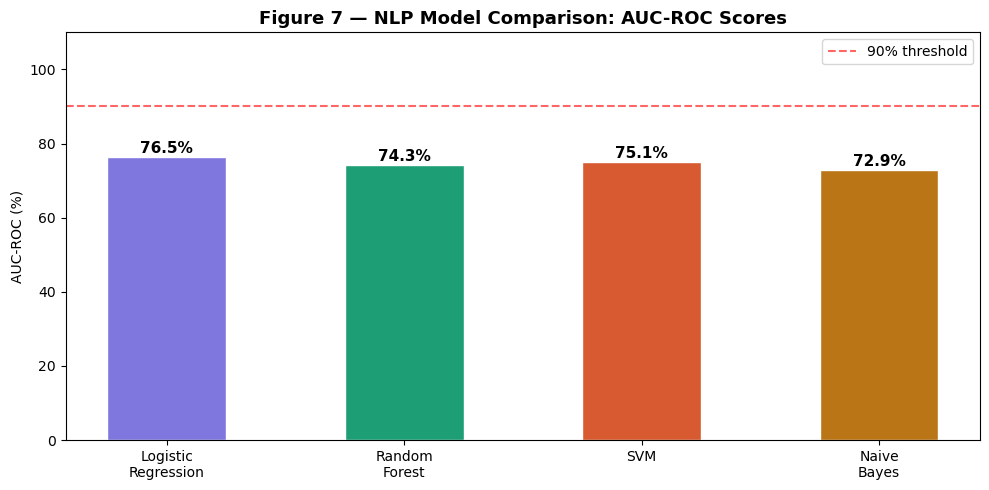

Saved: figure7_model_comparison.png
AUC scores: {'Logistic\nRegression': 76.5, 'Random\nForest': 74.3, 'SVM': 75.1, 'Naive\nBayes': 72.9}


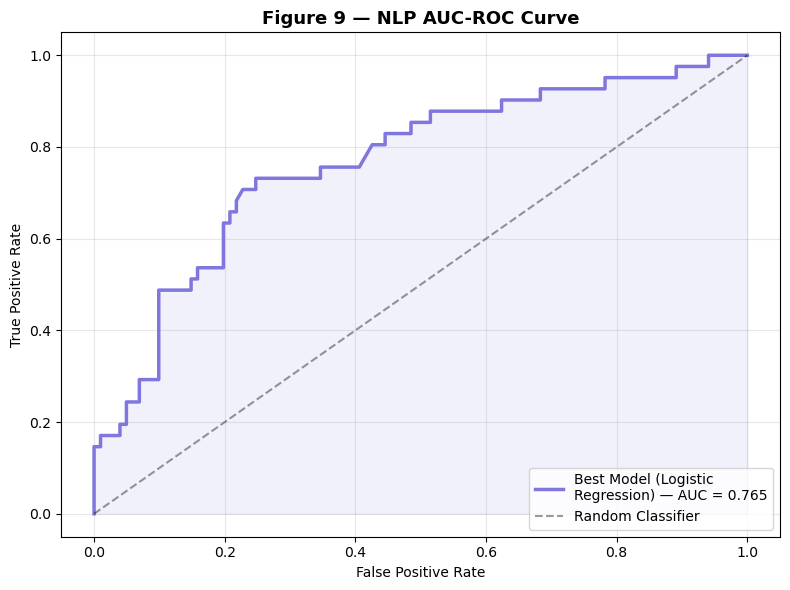

Saved: figure9_auc_roc_curve.png

=== FIGURES 7 & 9 SAVED ===
  figure7_model_comparison.png        51.2 KB
  figure9_auc_roc_curve.png           65.2 KB


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import os
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB

PATH = r"C:\Users\DELL\supply_chain_project\data"

news  = pd.read_csv(f"{PATH}/news_final_labelled.csv")
tfidf = pickle.load(open(f"{PATH}/tfidf_vectorizer.pkl", "rb"))
news["text"] = news["title"].fillna("") + " " + news["snippet"].fillna("")

# ── Figure 7 — NLP Model AUC-ROC Comparison ──────────────────────────────────
X = tfidf.transform(news["text"])
y = news["is_disruption"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

models = {
    "Logistic\nRegression": LogisticRegression(random_state=42, max_iter=1000),
    "Random\nForest":       RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM":                  SVC(probability=True, random_state=42),
    "Naive\nBayes":         MultinomialNB()
}
auc_scores = {}
trained_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    prob = model.predict_proba(X_test)[:, 1]
    auc_scores[name] = round(roc_auc_score(y_test, prob) * 100, 1)
    trained_models[name] = (model, prob)

colors_bar = ["#7F77DD", "#1D9E75", "#D85A30", "#BA7517"]
plt.figure(figsize=(10, 5))
bars = plt.bar(auc_scores.keys(), auc_scores.values(),
               color=colors_bar, edgecolor="white", width=0.5)
plt.title("Figure 7 — NLP Model Comparison: AUC-ROC Scores",
          fontsize=13, fontweight="bold")
plt.ylabel("AUC-ROC (%)")
plt.ylim(0, 110)
plt.axhline(90, color="red", linestyle="--", alpha=0.6, label="90% threshold")
plt.legend()
for bar, val in zip(bars, auc_scores.values()):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f"{val}%", ha="center", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.savefig(f"{PATH}/figure7_model_comparison.png", dpi=150)
plt.show()
print("Saved: figure7_model_comparison.png")
print("AUC scores:", auc_scores)

# ── Figure 9 — AUC-ROC Curve (best model) ────────────────────────────────────
best_name = max(auc_scores, key=auc_scores.get)
best_model, best_prob = trained_models[best_name]
fpr, tpr, _ = roc_curve(y_test, best_prob)
auc = roc_auc_score(y_test, best_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color="#7F77DD", linewidth=2.5,
         label=f"Best Model ({best_name.strip()}) — AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4, label="Random Classifier")
plt.fill_between(fpr, tpr, alpha=0.1, color="#7F77DD")
plt.title("Figure 9 — NLP AUC-ROC Curve", fontsize=13, fontweight="bold")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{PATH}/figure9_auc_roc_curve.png", dpi=150)
plt.show()
print("Saved: figure9_auc_roc_curve.png")

# ── Summary ───────────────────────────────────────────────────────────────────
print("\n=== FIGURES 7 & 9 SAVED ===")
for f in ["figure7_model_comparison.png", "figure9_auc_roc_curve.png"]:
    p = os.path.join(PATH, f)
    print(f"  {f:35} {os.path.getsize(p)/1024:.1f} KB")

In [ ]:
import pandas as pd
df = pd.read_csv("news_final_labelled.csv")
print(df['source'].value_counts())

In [ ]:
import os
for root, dirs, files in os.walk(os.getcwd()):
    for f in files:
        if f.endswith('.csv') and 'news' in f.lower():
            print(os.path.join(root, f))

In [ ]:
import pandas as pd
df = pd.read_csv(r"C:\Users\DELL\supply_chain_project\data\news_final_labelled.csv")
print(len(df))
print(df['source'].value_counts())

In [ ]:
"""
Generates all 10 tables for the Supply Chain report from your saved project files.
Update the file paths in the CONFIG section to match your actual folder
(C:\\Users\\DELL\\supply_chain_project\\data\\ ...).

Run this locally where your CSV/pkl files live. Each table prints to console
and also saves as a .csv you can paste straight into Word (Insert > Table >
Convert Text to Table, or open the csv and copy the grid).
"""

import pandas as pd
import pickle
import os

# ============ CONFIG - update these paths ============
DATA_DIR = r"C:\Users\DELL\supply_chain_project\data"
MODEL_DIR = r"C:\Users\DELL\supply_chain_project\models"   # adjust if different
OUT_DIR = r"C:\Users\DELL\supply_chain_project\report_tables"

MSME_MASTER = os.path.join(DATA_DIR, "msme_master.csv")
MSME_SECTOR_SUMMARY = os.path.join(DATA_DIR, "msme_sector_summary.csv")

# IMPORTANT: confirm which file is actually the 379-row version your report
# text refers to before using it here (see earlier count mismatch: 545 vs
# 636 vs 379). Swap this to whichever file len() == 379, or update your
# report text to match whichever file is correct.
NEWS_FILE = os.path.join(DATA_DIR, "news_final_labelled.csv")

GNN_RISK_SCORES = os.path.join(DATA_DIR, "gnn_node_risk_scores.csv")
RESILIENCE_SCORES = os.path.join(DATA_DIR, "msme_resilience_scores_v2.csv")
EDGE_LIST = os.path.join(DATA_DIR, "supply_chain_edges.csv")  # adjust filename if different

os.makedirs(OUT_DIR, exist_ok=True)


def save(df, name):
    path = os.path.join(OUT_DIR, f"{name}.csv")
    df.to_csv(path, index=False)
    print(f"\n{'='*70}\n{name}\n{'='*70}")
    print(df.to_string(index=False))
    print(f"-> saved to {path}")


# ============ Table 1: MSME Registration Data by City ============
def table1():
    df = pd.read_csv(MSME_MASTER)
    # adjust column names below to match your actual csv headers
    t1 = df.groupby("City").agg(
        Total_MSMEs=("EnterpriseName", "count")
    ).reset_index().sort_values("Total_MSMEs", ascending=False)
    save(t1, "Table1_MSME_by_City")


# ============ Table 2: NIC Code to Sector Mapping ============
def table2():
    # Use the same NIC->sector dict you built during preprocessing.
    # Paste it here (or load it if you saved it as a pickle/json).
    # Example structure - replace with your real mapping:
    nic_map = {
        # "01": "Agriculture", "10": "Food Processing", ... (all 29 sectors)
    }
    t2 = pd.DataFrame(list(nic_map.items()), columns=["NIC_2Digit_Code", "Sector"])
    save(t2, "Table2_NIC_Sector_Mapping")


# ============ Table 3: News Data Collection Summary by Source ============
def table3():
    df = pd.read_csv(NEWS_FILE)
    print(f"\nRow count in {NEWS_FILE}: {len(df)}  <- confirm this matches your report text")

    # group raw domains into your 5 report-level source buckets
    def bucket(src):
        src = str(src).lower()
        if "et_" in src or "economictimes" in src:
            return "Economic Times"
        if "hindu" in src:
            return "The Hindu"
        if "livemint" in src or "mint" in src:
            return "LiveMint"
        if "newsdata" in src:
            return "NewsData.io"
        return "Other/GDELT"

    df["source_group"] = df["source"].apply(bucket)
    t3 = df["source_group"].value_counts().reset_index()
    t3.columns = ["Source", "Articles"]
    t3["% of Total"] = (t3["Articles"] / t3["Articles"].sum() * 100).round(1)
    save(t3, "Table3_News_by_Source")


# ============ Table 4: Disruption Category Keywords ============
def table4():
    # Use the same keyword lists you used to label the 6 categories.
    # Replace with your actual keyword lists from the labelling script.
    keywords = {
        "Logistics": [],
        "Production": [],
        "Financial": [],
        "Natural": [],
        "Labour": [],
        "Policy": [],
    }
    rows = [{"Category": cat, "Keywords": ", ".join(words)} for cat, words in keywords.items()]
    t4 = pd.DataFrame(rows)
    save(t4, "Table4_Disruption_Keywords")


# ============ Table 5: NLP Model Comparison Results ============
def table5():
    # Rerun your Stage 3 evaluation and fill in the real numbers, e.g.:
    #
    # from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
    # results = []
    # for name, model in models.items():
    #     preds = model.predict(X_test)
    #     probs = model.predict_proba(X_test)[:, 1]
    #     results.append({
    #         "Model": name,
    #         "Accuracy": accuracy_score(y_test, preds),
    #         "F1_Score": f1_score(y_test, preds),
    #         "AUC_ROC": roc_auc_score(y_test, probs),
    #     })
    # t5 = pd.DataFrame(results)
    #
    # NOTE: check this against the 96%/0.963 vs ~70-76% AUC-ROC mismatch
    # flagged earlier before finalizing this table.
    t5 = pd.DataFrame(columns=["Model", "Accuracy", "F1_Score", "AUC_ROC"])
    save(t5, "Table5_NLP_Model_Comparison")


# ============ Table 6: Supply Chain Graph Edge List ============
def table6():
    df = pd.read_csv(EDGE_LIST)  # or rebuild from your NetworkX graph:
    # import networkx as nx
    # G = nx.read_gexf("supply_chain_graph.gexf")
    # df = pd.DataFrame(G.edges(), columns=["Source_Node", "Target_Node"])
    save(df, "Table6_Edge_List")


# ============ Table 7: GNN Node Feature Matrix (sample) ============
def table7():
    # Pull a sample of node features from your PyTorch Geometric Data object
    # import torch
    # data = torch.load("graph_data.pt")
    # t7 = pd.DataFrame(data.x.numpy()[:10], columns=[...feature names...])
    t7 = pd.DataFrame()  # fill in from your saved graph Data object
    save(t7, "Table7_GNN_Node_Features_Sample")


# ============ Table 8: Top 10 Highest Risk MSME Clusters (GNN) ============
def table8():
    df = pd.read_csv(GNN_RISK_SCORES)
    t8 = df.sort_values("gnn_risk_score", ascending=False).head(10).reset_index(drop=True)
    t8.insert(0, "Rank", range(1, 11))
    save(t8, "Table8_Top10_Risk_Clusters")


# ============ Table 9: Resilience Score Summary Statistics ============
def table9():
    df = pd.read_csv(RESILIENCE_SCORES)
    score_col = "Resilience_Score_v2"  # adjust if your column is named differently
    t9 = df[score_col].describe().reset_index()
    t9.columns = ["Statistic", "Value"]
    save(t9, "Table9_Resilience_Summary_Stats")


# ============ Table 10: Complete Resilience Score Table (186 clusters) ============
def table10():
    df = pd.read_csv(RESILIENCE_SCORES)
    save(df, "Table10_Complete_Resilience_Scores")


if __name__ == "__main__":
    for fn in [table1, table2, table3, table4, table5, table6, table7, table8, table9, table10]:
        try:
            fn()
        except Exception as e:
            print(f"\n[SKIPPED] {fn.__name__}: {e}")

In [1]:
pip install python-dotenv

Note: you may need to restart the kernel to use updated packages.
